In [1]:
import os
from pathlib import Path
from typing import List, Tuple, Dict, Optional, Sequence, Union
import random
import math
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import albumentations as A
from albumentations.pytorch import ToTensorV2
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# --------------------------- I/O helpers ---------------------------
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
MASK_EXTS = {".png", ".bmp", ".tif", ".tiff", ".jpg", ".jpeg"}

# Common mask name suffixes seen in polyp datasets
MASK_SUFFIXES = ("", "_mask", "_seg", "_polyp", "_gt", "-mask", "-seg", "-GT", "_ground_truth")

def _read_image_rgb(path: Path) -> np.ndarray:
    """Read image as RGB float32 (0..255)."""
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return img

def _read_mask_binary(path: Path) -> np.ndarray:
    """Read mask as binary (0,1) uint8."""
    m = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if m is None:
        raise FileNotFoundError(f"Could not read mask: {path}")
    # Some datasets use 255; some have multiple intensities—anything >0 is foreground
    m = (m > 0).astype(np.uint8)
    return m

def _canon_stem(stem: str) -> str:
    """Remove known mask suffixes to align image/mask stems."""
    for sfx in MASK_SUFFIXES:
        if sfx and stem.endswith(sfx):
            return stem[: -len(sfx)]
    return stem

def _scan_files(root: Path) -> Tuple[List[Path], List[Path]]:

    root = Path(root)

    # Prefer explicit subfolders if present
    img_dirs = [p for name in ("images", "image", "img", "original", "frames") for p in root.rglob(name) if p.is_dir()]
    msk_dirs = [p for name in ("masks", "mask", "ground_truth", "ground truth", "gt") for p in root.rglob(name) if p.is_dir()]

    if not img_dirs:
        img_dirs = [root]
    if not msk_dirs:
        msk_dirs = [root]

    def collect(paths, exts):
        out = []
        for d in paths:
            for p in d.rglob("*"):
                if p.is_file() and p.suffix.lower() in exts:
                    out.append(p)
        return out

    imgs = collect(img_dirs, IMG_EXTS)
    masks = collect(msk_dirs, MASK_EXTS)
    return imgs, masks

def find_image_mask_pairs(
    root: Union[str, Path],
    strict: bool = True,
) -> List[Tuple[Path, Path]]:

    imgs, masks = _scan_files(Path(root))
    mask_map: Dict[str, Path] = {}
    for m in masks:
        mask_map[_canon_stem(m.stem)] = m

    pairs = []
    for img in imgs:
        stem = _canon_stem(img.stem)
        if stem in mask_map:
            pairs.append((img, mask_map[stem]))
        elif not strict:
            # allow fallback by trying to find mask with any known suffix
            found = None
            for sfx in MASK_SUFFIXES:
                if (img.with_name(img.stem + sfx).with_suffix(".png")).exists():
                    found = img.with_name(img.stem + sfx).with_suffix(".png")
                    break
            if found is not None:
                pairs.append((img, found))

    if strict and not pairs:
        raise RuntimeError(f"No image/mask pairs found under {root}. "
                           f"Check folder structure or file naming.")
    # Deduplicate & sort
    pairs = sorted(list(set(pairs)))
    return pairs

# --------------------------- Visualization Helper ---------------------------
def show_batch_grid(imgs, masks, n=4):
    """
    Show n samples as a 2 x n grid:
      - Top row: images
      - Bottom row: corresponding masks
    """
    imgs = imgs[:n]
    masks = masks[:n]

    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])

    fig, axes = plt.subplots(2, n, figsize=(4*n, 6))

    # If n == 1, axes will be 1D; normalize to 2D
    if n == 1:
        axes = np.expand_dims(axes, axis=1)

    for i in range(n):
        # ----- image -----
        img = imgs[i].permute(1, 2, 0).cpu().numpy()  # [H,W,3]
        img = img * std + mean                         # de-normalize
        img = np.clip(img, 0, 1)

        axes[0, i].imshow(img)
        axes[0, i].set_title(f"Image {i}")
        axes[0, i].axis("off")

        # ----- mask -----
        mask = masks[i, 0].cpu().numpy()               # [H,W]
        axes[1, i].imshow(mask, cmap="gray")
        axes[1, i].set_title(f"Mask {i}")
        axes[1, i].axis("off")

    plt.tight_layout()
    plt.show()

In [2]:
# --------------------------- Transforms ---------------------------
import albumentations as A
from albumentations.pytorch import ToTensorV2
import cv2
from typing import List

import albumentations as A
import cv2

def make_transforms(image_size=512, train=True, normalize=True, clahe=True):
    t = []
    
    # Basic resizing
    t += [A.Resize(image_size, image_size, interpolation=cv2.INTER_LINEAR)]
    
    if train:
        t += [
            # Geometric augmentations
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.3),
            A.RandomRotate90(p=0.5),
            A.Affine(
                translate_percent=(0.05, 0.05),  # Correct translation limits
                scale=0.10,                      # Correct scale parameter
                rotate=15,                 # Correct rotation limit
                cval=0, 
                p=0.5
            ),
            
            # More intense geometric distortions - safely limited
            A.OneOf([
                A.ElasticTransform(alpha=10, sigma=5, p=0.5),
                A.GridDistortion(num_steps=5, distort_limit=0.3, p=0.5),
                A.OpticalDistortion(distort_limit=0.35, p=0.5),
            ], p=0.5),
            
            # Photometric augmentations
            A.OneOf([
                A.RandomBrightnessContrast(brightness_limit=0.25, contrast_limit=0.2, p=0.5),
                A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=1.0) if clahe else A.NoOp(),
            ], p=0.5),
            A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=15, val_shift_limit=10, p=0.5),
            A.OneOf([
                A.GaussianBlur(blur_limit=3, p=0.5),
                A.MotionBlur(blur_limit=3, p=0.5),
            ], p=0.15),
            
            # Noise & compression
            A.GaussNoise(var_limit=(5.0, 10.0), p=0.5),
            A.ImageCompression(quality_lower=60, quality_upper=80, p=0.5),
        ]
    
    if normalize:
        t += [A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))]
    
    # Convert to tensor
    t += [A.pytorch.ToTensorV2()]
    
    return A.Compose(t)

In [3]:
# --------------------------- Dataset ---------------------------
class PolypDataset(Dataset):

    def __init__(
        self,
        pairs: Sequence[Tuple[Path, Path]],
        transform: Optional[A.Compose] = None,
        return_path: bool = False,
    ):
        self.pairs = list(pairs)
        self.transform = transform if transform is not None else make_transforms()
        self.return_path = return_path

        # Precompute which samples are positive (mask contains any foreground)
        self._is_pos = []
        for _, m in self.pairs:
            try:
                mm = _read_mask_binary(m)
                self._is_pos.append(int(mm.sum() > 0))
            except Exception:
                self._is_pos.append(0)

    def __len__(self) -> int:
        return len(self.pairs)

    def is_positive(self, idx: int) -> bool:
        return bool(self._is_pos[idx])

    def __getitem__(self, idx: int):
        img_path, mask_path = self.pairs[idx]
        img = _read_image_rgb(img_path)
        mask = _read_mask_binary(mask_path)

        # Albumentations expects HWC; mask is HW
        if self.transform is not None:
            transformed = self.transform(image=img, mask=mask)
            img_t = transformed["image"]          # torch.FloatTensor [3,H,W]
            mask_t = transformed["mask"].unsqueeze(0)  # [1,H,W]
        else:
            # fallback to tensor without aug
            img = img.astype(np.float32) / 255.0
            img_t = torch.from_numpy(np.transpose(img, (2,0,1)))
            mask_t = torch.from_numpy(mask[None, ...].astype(np.float32))

        mask_t = (mask_t > 0.5).float()  # ensure binary float

        if self.return_path:
            return img_t, mask_t, str(img_path), str(mask_path)
        return img_t, mask_t

In [4]:
def build_weighted_sampler(
    dataset: PolypDataset,
    target_pos_fraction: float = 0.5,
    replace: bool = True,
) -> Optional[WeightedRandomSampler]:

    assert 0.0 < target_pos_fraction < 1.0, "target_pos_fraction must be in (0,1)"
    labels = np.array([dataset.is_positive(i) for i in range(len(dataset))], dtype=np.float32)
    pos = labels.sum()
    neg = len(labels) - pos
    if pos == 0 or neg == 0:
        # Degenerate; no need to reweight
        return None
    p_emp = pos / len(labels)
    # Weights that solve sampling mix ~ target_pos_fraction:
    w_pos = (target_pos_fraction / p_emp)
    w_neg = ((1.0 - target_pos_fraction) / (1.0 - p_emp))
    weights = np.where(labels > 0, w_pos, w_neg).astype(np.float64)
    return WeightedRandomSampler(weights=weights, num_samples=len(labels), replacement=replace)

In [5]:
# --------------------------- Polygap Dataset Structure ---------------------------
import os
from sklearn.model_selection import train_test_split

def make_polygap_loaders(
    polygap_root: Union[str, Path],
    image_size: int = 512,
    batch_size: int = 6,
    val_split: float = 0.2,  # Split ratio from train_set to create validation
    seed: int = 42,
    num_workers: int = 0,
    pin_memory: bool = True,
    pos_fraction: Optional[float] = None,
    normalize: bool = True,
    clahe: bool = True,
) -> Dict[str, Dict[str, DataLoader]]:
    """
    Create data loaders for Polygap dataset structure.
    
    Returns:
        {
            'train': DataLoader,
            'val': DataLoader,
            'test_sets': {
                'Kvasir-SEG': DataLoader,
                'CVC-ClinicDB': DataLoader,
                'CVC-ColonDB': DataLoader,
                'ETIS-LaribPolypDB': DataLoader,
                'CVC-T': DataLoader
            }
        }
    """
    polygap_root = Path(polygap_root)
    
    # 1. Handle training set (needs train/val split)
    train_set_path = polygap_root / "train_set"
    train_img_dir = train_set_path / "images"
    train_mask_dir = train_set_path / "masks"
    
    if not train_img_dir.exists() or not train_mask_dir.exists():
        raise FileNotFoundError(f"Polygap train_set not found at {train_set_path}")
    
    # Get all image-mask pairs from train_set
    train_pairs = []
    train_images = sorted(os.listdir(train_img_dir))
    train_masks = sorted(os.listdir(train_mask_dir))
    
    # Match image and mask files (assuming same filenames)
    for img_name in train_images:
        mask_name = img_name  # Assuming same name, adjust if different
        if mask_name not in train_masks:
            # Try with different extensions or patterns
            mask_candidates = [m for m in train_masks if m.startswith(img_name.split('.')[0])]
            if mask_candidates:
                mask_name = mask_candidates[0]
            else:
                print(f"Warning: No mask found for {img_name}")
                continue
        
        img_path = train_img_dir / img_name
        mask_path = train_mask_dir / mask_name
        
        if img_path.exists() and mask_path.exists():
            train_pairs.append((img_path, mask_path))
        else:
            print(f"Warning: Missing file for {img_name}")
    
    print(f"Found {len(train_pairs)} pairs in train_set")
    
    # 2. Split train_set into actual training and validation
    train_indices, val_indices = train_test_split(
        list(range(len(train_pairs))),
        test_size=val_split,
        random_state=seed,
        shuffle=True
    )
    
    pairs_train = [train_pairs[i] for i in train_indices]
    pairs_val = [train_pairs[i] for i in val_indices]
    
    # 3. Handle test sets (5 different datasets)
    test_sets_root = polygap_root / "test_set"
    test_datasets = {}
    
    # Define the 5 test dataset names as in Polygap structure
    test_dataset_names = [
        "Kvasir",           # Your dataset has "Kvasir" not "Kvasir-SEG"
        "CVC-ClinicDB", 
        "CVC-ColonDB",
        "ETIS-LaribPolypDB",
        "CVC-300"           # Your dataset has "CVC-300" not "CVC-T"
    ]
    
    for dataset_name in test_dataset_names:
        dataset_path = test_sets_root / dataset_name
        img_dir = dataset_path / "images"
        mask_dir = dataset_path / "masks"
        
        if not img_dir.exists() or not mask_dir.exists():
            print(f"Warning: Test dataset {dataset_name} not found at {dataset_path}")
            continue
        
        # Get pairs for this test dataset
        test_pairs = []
        test_images = sorted(os.listdir(img_dir))
        test_masks = sorted(os.listdir(mask_dir))
        
        for img_name in test_images:
            mask_name = img_name  # Adjust if naming pattern is different
            if mask_name not in test_masks:
                # Try to find matching mask
                img_stem = Path(img_name).stem
                mask_candidates = [m for m in test_masks if Path(m).stem.startswith(img_stem)]
                if mask_candidates:
                    mask_name = mask_candidates[0]
                else:
                    continue
            
            img_path = img_dir / img_name
            mask_path = mask_dir / mask_name
            
            if img_path.exists() and mask_path.exists():
                test_pairs.append((img_path, mask_path))
        
        print(f"Found {len(test_pairs)} pairs in test dataset: {dataset_name}")
        test_datasets[dataset_name] = test_pairs
    
    # 4. Create transforms
    tf_train = make_transforms(image_size=image_size, train=True, normalize=normalize, clahe=clahe)
    tf_eval = make_transforms(image_size=image_size, train=False, normalize=normalize, clahe=False)
    
    # 5. Create datasets
    ds_train = PolypDataset(pairs_train, transform=tf_train)
    ds_val = PolypDataset(pairs_val, transform=tf_eval)
    
    # Optional positive-oversampling sampler for training
    sampler = None
    shuffle = True
    if pos_fraction is not None:
        sampler = build_weighted_sampler(ds_train, target_pos_fraction=pos_fraction, replace=True)
        shuffle = sampler is None
    
    # 6. Create data loaders
    dl_train = DataLoader(ds_train, batch_size=batch_size, shuffle=shuffle, sampler=sampler,
                         num_workers=num_workers, pin_memory=pin_memory, drop_last=False)
    dl_val = DataLoader(ds_val, batch_size=batch_size, shuffle=False,
                       num_workers=num_workers, pin_memory=pin_memory, drop_last=False)
    
    # 7. Create test loaders for each dataset
    dl_test_sets = {}
    for dataset_name, pairs in test_datasets.items():
        if len(pairs) > 0:
            ds_test = PolypDataset(pairs, transform=tf_eval)
            dl_test = DataLoader(ds_test, batch_size=batch_size, shuffle=False,
                               num_workers=num_workers, pin_memory=pin_memory, drop_last=False)
            dl_test_sets[dataset_name] = dl_test
        else:
            print(f"Warning: No pairs for test dataset {dataset_name}, skipping loader")
    
    return {
        "train": dl_train,
        "val": dl_val,
        "test_sets": dl_test_sets
    }

In [6]:
def inspect_polygap_structure(polygap_root: Union[str, Path]):
    """Inspect the Polygap dataset structure and print summary."""
    polygap_root = Path(polygap_root)
    
    print("=" * 60)
    print("Polygap Dataset Structure Inspection")
    print("=" * 60)
    
    # Check train_set
    train_set_path = polygap_root / "train_set"
    if train_set_path.exists():
        train_images = sorted(os.listdir(train_set_path / "images"))
        train_masks = sorted(os.listdir(train_set_path / "masks"))
        print(f"\n1. train_set/")
        print(f"   ├── images/: {len(train_images)} files")
        print(f"   └── masks/:  {len(train_masks)} files")
        
        # Show first few filenames
        if train_images:
            print(f"      Sample images: {train_images[:3]}")
        if train_masks:
            print(f"      Sample masks:  {train_masks[:3]}")
    else:
        print(f"\nWarning: train_set not found at {train_set_path}")
    
    # Check test_set
    test_set_path = polygap_root / "test_set"
    if test_set_path.exists():
        print(f"\n2. test_set/")
        test_datasets = []
        for item in os.listdir(test_set_path):
            item_path = test_set_path / item
            if item_path.is_dir():
                images_dir = item_path / "images"
                masks_dir = item_path / "masks"
                if images_dir.exists() and masks_dir.exists():
                    num_images = len(os.listdir(images_dir))
                    num_masks = len(os.listdir(masks_dir))
                    test_datasets.append((item, num_images, num_masks))
        
        for dataset_name, num_img, num_mask in test_datasets:
            print(f"   ├── {dataset_name}/")
            print(f"   │   ├── images/: {num_img} files")
            print(f"   │   └── masks/:  {num_mask} files")
        
        print(f"\n   Found {len(test_datasets)} test datasets")
    else:
        print(f"\nWarning: test_set not found at {test_set_path}")
    
    print("=" * 60)

In [7]:
# Define your Polygap dataset path
POLYGAP_ROOT = "C:/Users/CDUT-Lab-Prof.Cai/Desktop/Segmentation_Medical/SeG-Pach/Datasets/Poly_New"  # UPDATE THIS PATH

# Inspect the structure first
inspect_polygap_structure(POLYGAP_ROOT)

# Create Polygap loaders
loaders = make_polygap_loaders(
    polygap_root=POLYGAP_ROOT,
    image_size=512,
    batch_size=6,
    val_split=0.2,  # 10% of train_set for validation
    seed=42,
    num_workers=0,
    pos_fraction=0.5,  # or 0.5 if you want sampler
    normalize=True,
    clahe=True,
)

# Access the loaders
dl_train = loaders["train"]
dl_val = loaders["val"]
dl_test_sets = loaders["test_sets"]

print(f"\nTraining batches: {len(dl_train)}")
print(f"Validation batches: {len(dl_val)}")
print(f"\nTest datasets:")
for dataset_name, dl_test in dl_test_sets.items():
    print(f"  - {dataset_name}: {len(dl_test)} batches")

Polygap Dataset Structure Inspection

1. train_set/
   ├── images/: 1450 files
   └── masks/:  1450 files
      Sample images: ['1.png', '10.png', '101.png']
      Sample masks:  ['1.png', '10.png', '101.png']

2. test_set/
   ├── CVC-300/
   │   ├── images/: 60 files
   │   └── masks/:  60 files
   ├── CVC-ClinicDB/
   │   ├── images/: 62 files
   │   └── masks/:  62 files
   ├── CVC-ColonDB/
   │   ├── images/: 380 files
   │   └── masks/:  380 files
   ├── ETIS-LaribPolypDB/
   │   ├── images/: 196 files
   │   └── masks/:  196 files
   ├── Kvasir/
   │   ├── images/: 100 files
   │   └── masks/:  100 files

   Found 5 test datasets
Found 1450 pairs in train_set
Found 100 pairs in test dataset: Kvasir
Found 62 pairs in test dataset: CVC-ClinicDB
Found 380 pairs in test dataset: CVC-ColonDB
Found 196 pairs in test dataset: ETIS-LaribPolypDB
Found 60 pairs in test dataset: CVC-300


c:\Users\CDUT-Lab-Prof.Cai\anaconda3\envs\pytorch_gpu\lib\site-packages\albumentations\augmentations\transforms.py:1952: UserWarning: blur_limit and sigma_limit minimum value can not be both equal to 0. blur_limit minimum value changed to 3.
  warnings.warn(



Training batches: 194
Validation batches: 49

Test datasets:
  - Kvasir: 17 batches
  - CVC-ClinicDB: 11 batches
  - CVC-ColonDB: 64 batches
  - ETIS-LaribPolypDB: 33 batches
  - CVC-300: 10 batches



Visualizing training batch...


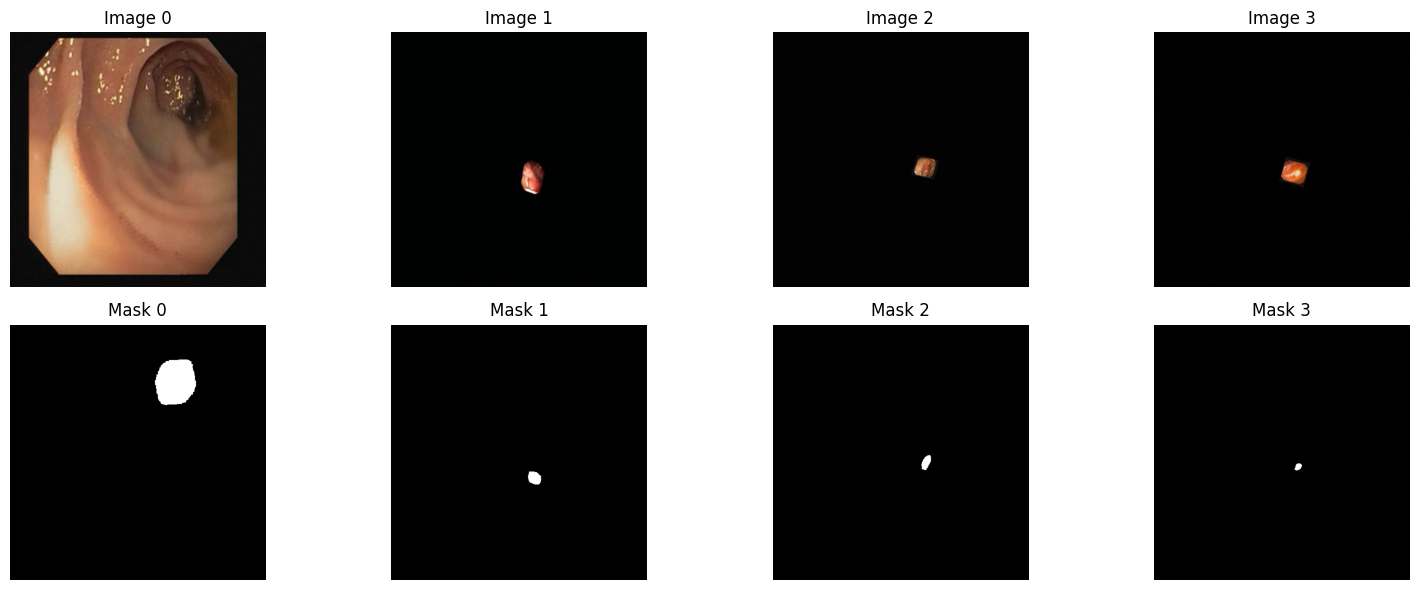

In [8]:
# Visualize a batch from training set
torch.manual_seed(42)
print("\nVisualizing training batch...")
batch = next(iter(dl_train))
imgs, masks = batch
show_batch_grid(imgs, masks, n=4)


Visualizing Test Datasets

Kvasir:


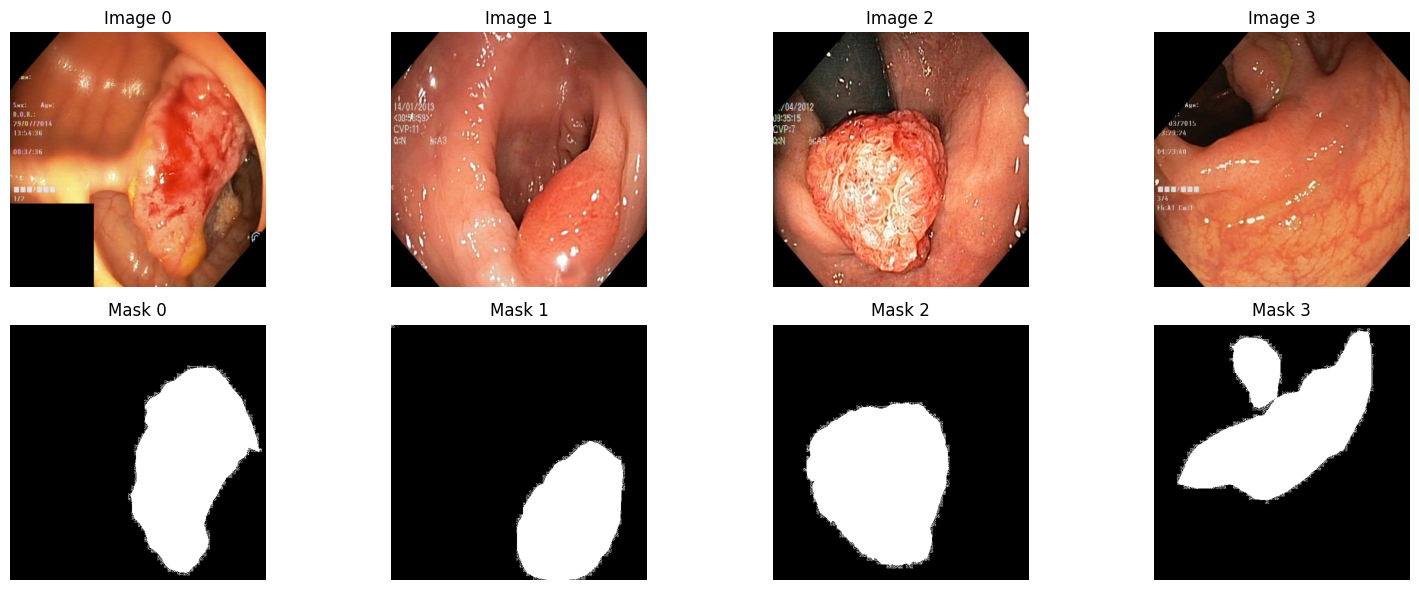


CVC-ClinicDB:


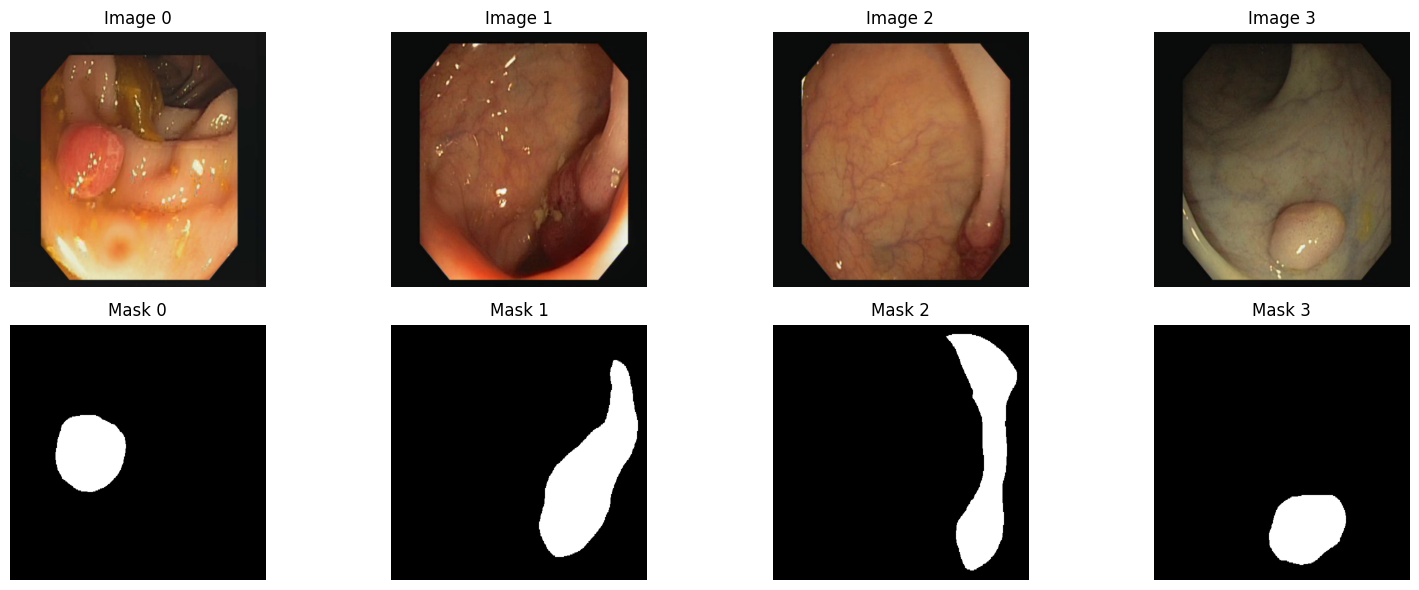


CVC-ColonDB:


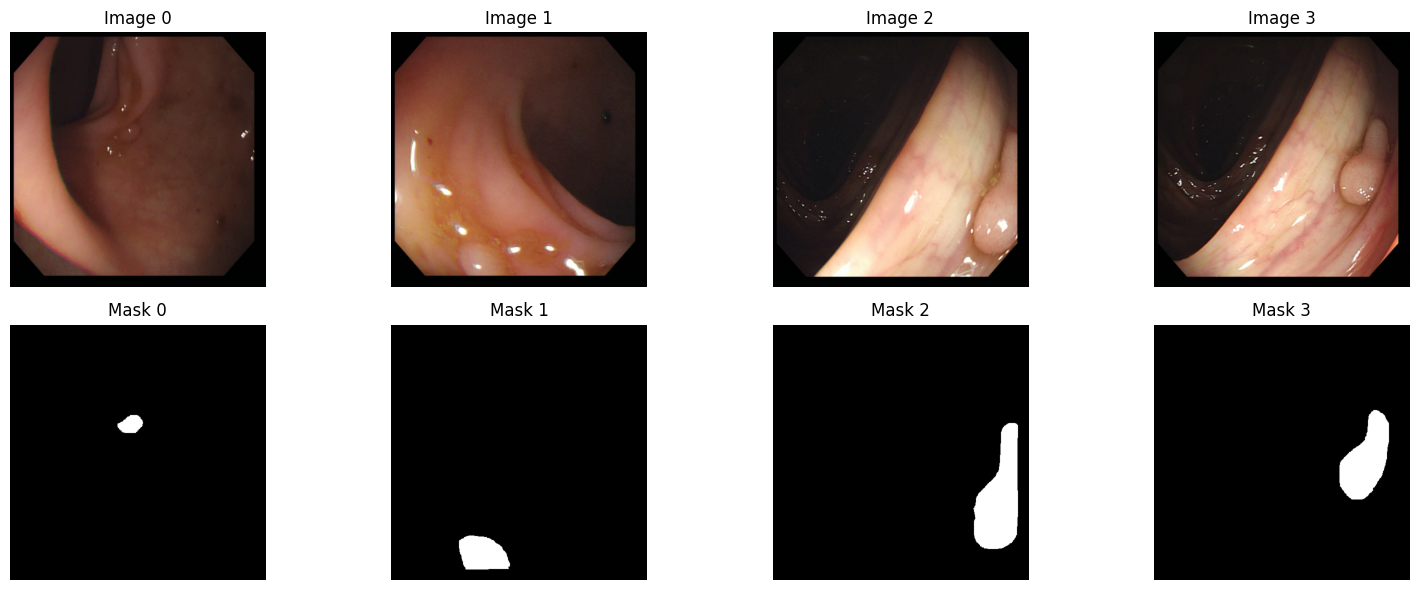


ETIS-LaribPolypDB:


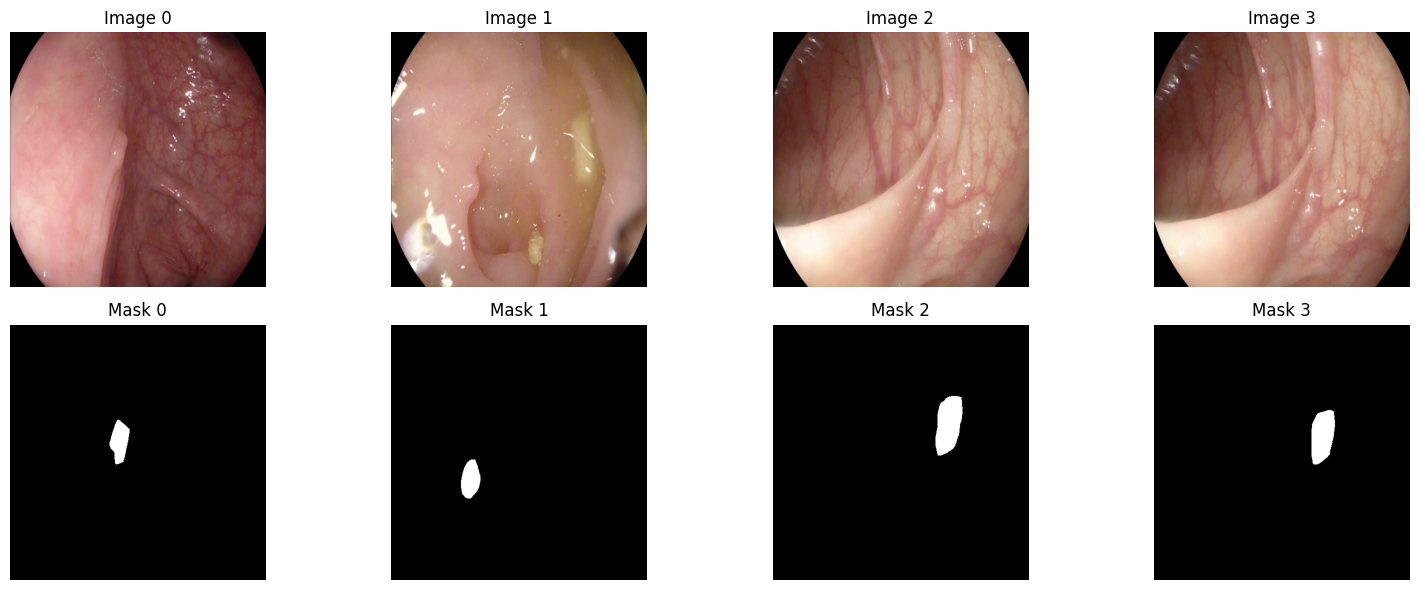


CVC-300:


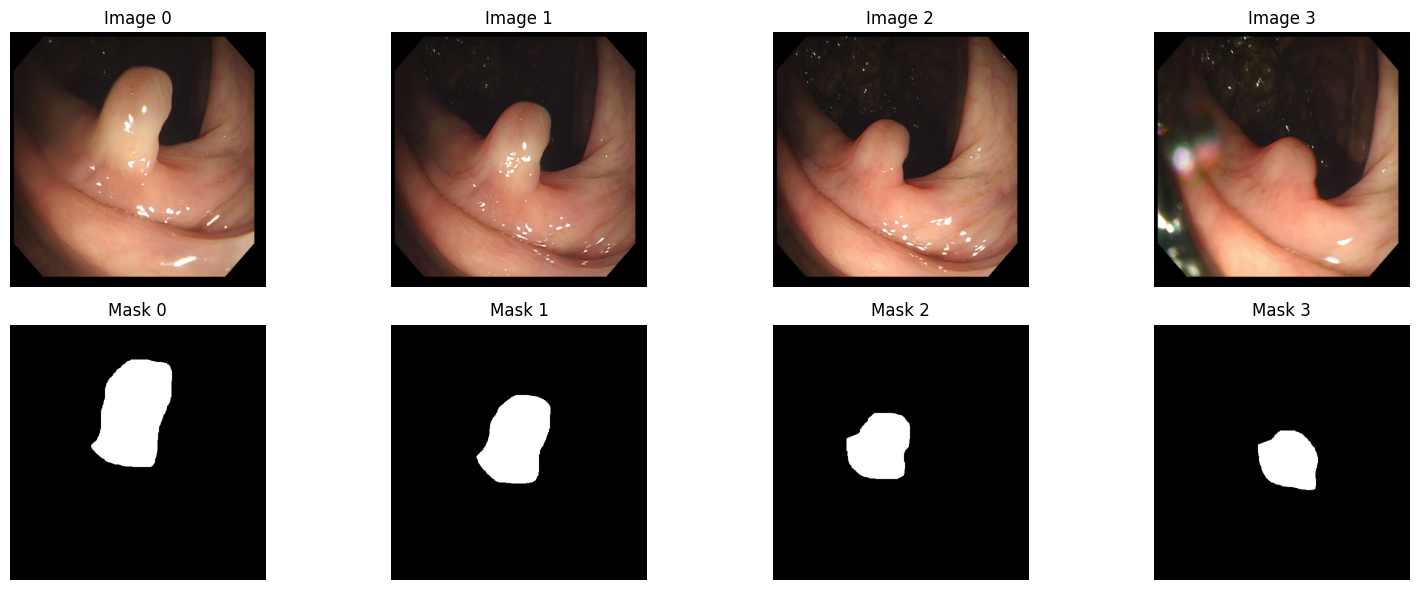

In [9]:
# Visualize samples from each test dataset
print("\n" + "="*60)
print("Visualizing Test Datasets")
print("="*60)

for dataset_name, dl_test in dl_test_sets.items():
    print(f"\n{dataset_name}:")
    try:
        torch.manual_seed(42)
        batch = next(iter(dl_test))
        imgs, masks = batch
        show_batch_grid(imgs, masks, n=min(4, len(imgs)))
    except Exception as e:
        print(f"  Error visualizing {dataset_name}: {e}")

## New Model

In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm

class Identity(nn.Module):
    def forward(self, x, *args, **kwargs):
        return x

class ConvBlock(nn.Module):
    def __init__(self, in_ch: int, out_ch: int, dropout_prob: float = 0.2):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.GELU(),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.GELU(),
            nn.Dropout(dropout_prob),
        )
    def forward(self, x): return self.conv(x)

class SSMBlock2D(nn.Module):
    def __init__(self, channels: int, expansion: int = 2, kernel_size: int = 7):
        super().__init__()
        hidden = channels * expansion
        self.norm = nn.GroupNorm(1, channels)
        self.proj_in = nn.Conv2d(channels, hidden, kernel_size=1, bias=True)
        self.dw_conv = nn.Conv2d(hidden, hidden, kernel_size=kernel_size,
                                 padding=kernel_size//2, groups=hidden, bias=True)
        self.proj_out = nn.Conv2d(hidden // 2, channels, kernel_size=1, bias=True)
        self.act = nn.GELU()

    def forward(self, x):
        residual = x
        x = self.norm(x)
        x = self.proj_in(x)
        x = self.dw_conv(x)
        u, v = torch.chunk(x, 2, dim=1)
        x = u * torch.sigmoid(v)
        x = self.proj_out(self.act(x))
        return x + residual

class AttentionModule(nn.Module):
    def __init__(self, channels, dropout_prob: float = 0.2):
        super().__init__()
        self.channel_attn = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(channels, channels // 16, 1),
            nn.GELU(),
            nn.Conv2d(channels // 16, channels, 1),
            nn.Sigmoid(),
            nn.Dropout(dropout_prob),
        )
        self.spatial_attn = nn.Sequential(
            nn.Conv2d(channels, 1, kernel_size=7, padding=3),
            nn.Sigmoid(),
        )

    def forward(self, x):
        x = self.channel_attn(x) * x
        x = self.spatial_attn(x) * x
        return x

class UpBlock(nn.Module):
    def __init__(self, in_ch: int, skip_ch: int, out_ch: int, use_attn=True, dropout_prob: float = 0.2):
        super().__init__()
        self.conv = ConvBlock(in_ch + skip_ch, out_ch, dropout_prob=dropout_prob)
        self.attn = AttentionModule(out_ch, dropout_prob=dropout_prob) if use_attn else Identity()

    def forward(self, x, skip):
        x = F.interpolate(x, size=skip.shape[2:], mode="bilinear", align_corners=False)
        x = torch.cat([x, skip], dim=1)
        x = self.conv(x)
        return self.attn(x)

class ResNet50Encoder(nn.Module):
    def __init__(self, pretrained=True, out_indices=(0,1,2,3)):
        super().__init__()
        self.encoder = timm.create_model("resnet50", pretrained=pretrained,
                                         features_only=True, out_indices=out_indices)
        self.out_channels = self.encoder.feature_info.channels()
    def forward(self, x): return self.encoder(x)

class PVTEncoder(nn.Module):
    def __init__(self, pretrained=True, out_indices=(0,1,2,3)):
        super().__init__()
        self.encoder = timm.create_model("pvt_v2_b2", pretrained=pretrained,
                                         features_only=True, out_indices=out_indices)
        self.out_channels = self.encoder.feature_info.channels()
    def forward(self, x): return self.encoder(x)

class MultiScalePool(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.pools = nn.ModuleList([
            nn.AdaptiveAvgPool2d((1,1)),
            nn.AdaptiveAvgPool2d((2,2)),
            nn.AdaptiveAvgPool2d((3,3)),
            nn.AdaptiveAvgPool2d((6,6)),
        ])
        self.conv = nn.Conv2d(channels*5, channels, kernel_size=1)

    def forward(self, x):
        pooled = [F.interpolate(p(x), size=x.shape[2:], mode="bilinear", align_corners=False) for p in self.pools]
        fused = torch.cat(pooled + [x], dim=1)
        return self.conv(fused)

class LiteSSMPolypNet(nn.Module):
    def __init__(self,
                 in_channels=3,
                 num_classes=1,
                 encoder_pretrained=True,
                 decoder_channels=256,
                 backbone="pvt",              # "pvt" or "resnet50"
                 use_msp=True,
                 use_ssm=True,
                 use_attn=True,
                 dropout_prob=0.2):
        super().__init__()

        if backbone.lower() == "pvt":
            self.encoder = PVTEncoder(pretrained=encoder_pretrained)
        elif backbone.lower() == "resnet50":
            self.encoder = ResNet50Encoder(pretrained=encoder_pretrained)
        else:
            raise ValueError("backbone must be 'pvt' or 'resnet50'")

        c0, c1, c2, c3 = self.encoder.out_channels

        d3 = decoder_channels
        d2 = decoder_channels // 2
        d1 = decoder_channels // 4
        d0 = decoder_channels // 4

        self.bottleneck_conv = ConvBlock(c3, d3, dropout_prob=dropout_prob)
        self.bottleneck_msp  = MultiScalePool(d3) if use_msp else Identity()
        self.bottleneck_ssm  = SSMBlock2D(d3) if use_ssm else Identity()

        self.up2  = UpBlock(d3, c2, d2, use_attn=use_attn, dropout_prob=dropout_prob)
        self.ssm2 = SSMBlock2D(d2) if use_ssm else Identity()

        self.up1  = UpBlock(d2, c1, d1, use_attn=use_attn, dropout_prob=dropout_prob)
        self.ssm1 = SSMBlock2D(d1) if use_ssm else Identity()

        self.up0  = UpBlock(d1, c0, d0, use_attn=use_attn, dropout_prob=dropout_prob)
        self.ssm0 = SSMBlock2D(d0) if use_ssm else Identity()

        self.head = nn.Conv2d(d0, num_classes, kernel_size=1)

    def forward(self, x):
        x0, x1, x2, x3 = self.encoder(x)

        b = self.bottleneck_conv(x3)
        b = self.bottleneck_msp(b)
        b = self.bottleneck_ssm(b)

        d2 = self.ssm2(self.up2(b, x2))
        d1 = self.ssm1(self.up1(d2, x1))
        d0 = self.ssm0(self.up0(d1, x0))

        logits = self.head(d0)
        if logits.shape[2:] != x.shape[2:]:
            logits = F.interpolate(logits, size=x.shape[2:], mode="bilinear", align_corners=False)
        return logits

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Define a dictionary mapping configurations to model parameters
model_configurations = {
    "A0_Full": {
        "backbone": "pvt",
        "use_msp": True,
        "use_ssm": True,
        "use_attn": True,
        "decoder_channels": 256
    },
    "A1_MSP": {
        "backbone": "pvt",
        "use_msp": False,
        "use_ssm": True,
        "use_attn": True,
        "decoder_channels": 256
    },
    "A2_SSM": {
        "backbone": "pvt",
        "use_msp": True,
        "use_ssm": False,
        "use_attn": True,
        "decoder_channels": 256
    },
    "A3_Attn": {
        "backbone": "pvt",
        "use_msp": True,
        "use_ssm": True,
        "use_attn": False,
        "decoder_channels": 256
    },
    "A4_Backbone_swap": {
        "backbone": "resnet50",
        "use_msp": True,
        "use_ssm": True,
        "use_attn": True,
        "decoder_channels": 256
    },
    "A5_Decoder_width": {
        "backbone": "pvt",
        "use_msp": True,
        "use_ssm": True,
        "use_attn": True,
        "decoder_channels": 128
    }
}

# Select the configuration
selected_config = "A3_Attn"  # Replace with any of the keys from the dictionary

# Get the model parameters based on the selected configuration
config = model_configurations[selected_config]

# Instantiate the model with the selected parameters
model = LiteSSMPolypNet(
    backbone=config["backbone"],
    use_msp=config["use_msp"],
    use_ssm=config["use_ssm"],
    use_attn=config["use_attn"],
    decoder_channels=config["decoder_channels"]
).to(device)

# Print the number of parameters for the selected model
total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params/1e6:.2f} M")

# One batch from your train loader
batch = next(iter(dl_train))
imgs, masks = batch  # [B,3,H,W] and [B,1,H,W]
imgs = imgs.to(device)

with torch.no_grad():
    logits = model(imgs)

print("Input shape:", imgs.shape)
print("Logits shape:", logits.shape)

Total parameters: 28.38 M
Input shape: torch.Size([6, 3, 512, 512])
Logits shape: torch.Size([6, 1, 512, 512])


In [12]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from sklearn.metrics import fbeta_score
from collections import defaultdict
from tqdm import tqdm
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy.spatial.distance import directed_hausdorff
from scipy.ndimage import binary_erosion, binary_dilation

# --------------------------- COMPREHENSIVE METRICS CLASS ---------------------------
class SegmentationMetrics:
    def __init__(self, num_classes=2, device='cuda' if torch.cuda.is_available() else 'cpu'):
        self.num_classes = num_classes
        self.device = device
        self.metric_names = [
            'Dice', 'IoU', 'Sensitivity', 'Specificity', 
            'Precision', 'Accuracy', 'F2_Score',
            'Hausdorff95', 'ASSD', 'RVD'
        ]
    
    def calculate_all(self, pred, target, smooth=1e-6):
        """
        Calculate all 10 metrics for a batch
        Args:
            pred: (B, H, W) or (B, 1, H, W) - binary predictions [0 or 1]
            target: (B, H, W) or (B, 1, H, W) - binary ground truth [0 or 1]
        Returns:
            Dictionary with all 10 metrics
        """
        # Ensure binary tensors
        if len(pred.shape) == 4:
            pred = pred.squeeze(1)
        if len(target.shape) == 4:
            target = target.squeeze(1)
        
        # Flatten for most metrics
        pred_flat = pred.flatten()
        target_flat = target.flatten()
        
        # Calculate confusion matrix components
        tp = ((pred_flat == 1) & (target_flat == 1)).sum().float()
        tn = ((pred_flat == 0) & (target_flat == 0)).sum().float()
        fp = ((pred_flat == 1) & (target_flat == 0)).sum().float()
        fn = ((pred_flat == 0) & (target_flat == 1)).sum().float()
        
        # 1. Dice Coefficient
        dice = (2 * tp + smooth) / (2 * tp + fp + fn + smooth)
        
        # 2. IoU (Jaccard)
        iou = (tp + smooth) / (tp + fp + fn + smooth)
        
        # 3. Sensitivity (Recall)
        sensitivity = (tp + smooth) / (tp + fn + smooth)
        
        # 4. Specificity
        specificity = (tn + smooth) / (tn + fp + smooth)
        
        # 5. Precision
        precision = (tp + smooth) / (tp + fp + smooth)
        
        # 6. Accuracy
        accuracy = (tp + tn + smooth) / (tp + tn + fp + fn + smooth)
        
        # 7. F2-Score (beta=2, emphasizes recall)
        beta = 2
        f2_score = (1 + beta**2) * (precision * sensitivity) / (beta**2 * precision + sensitivity + smooth)
        
        # 8. Hausdorff Distance (95%) - requires per-instance calculation
        hd95 = self._calculate_hd95_batch(pred, target)
        
        # 9. Average Symmetric Surface Distance
        assd = self._calculate_assd_batch(pred, target)
        
        # 10. Relative Volume Difference
        rvd = self._calculate_rvd_batch(pred, target)
        
        return {
            'Dice': dice.item(),
            'IoU': iou.item(),
            'Sensitivity': sensitivity.item(),
            'Specificity': specificity.item(),
            'Precision': precision.item(),
            'Accuracy': accuracy.item(),
            'F2_Score': f2_score.item(),
            'Hausdorff95': hd95,
            'ASSD': assd,
            'RVD': rvd
        }
    
    def _calculate_hd95_batch(self, pred, target):
        """Calculate 95th percentile Hausdorff Distance for batch"""
        hd_distances = []
        batch_size = pred.shape[0]
        
        for i in range(batch_size):
            pred_mask = pred[i].cpu().numpy()
            target_mask = target[i].cpu().numpy()
            
            # Get boundary points
            pred_boundary = self._get_boundary_points(pred_mask)
            target_boundary = self._get_boundary_points(target_mask)
            
            if len(pred_boundary) == 0 or len(target_boundary) == 0:
                hd_distances.append(0)
                continue
            
            # Calculate Hausdorff distance
            hd = directed_hausdorff(pred_boundary, target_boundary)[0]
            hd_reverse = directed_hausdorff(target_boundary, pred_boundary)[0]
            hd_distances.append(max(hd, hd_reverse))
        
        # Return 95th percentile (or mean if small batch)
        if len(hd_distances) > 0:
            return np.percentile(hd_distances, 95) if len(hd_distances) >= 5 else np.mean(hd_distances)
        return 0.0
    
    def _calculate_assd_batch(self, pred, target):
        """Calculate Average Symmetric Surface Distance for batch"""
        assd_values = []
        batch_size = pred.shape[0]
        
        for i in range(batch_size):
            pred_mask = pred[i].cpu().numpy()
            target_mask = target[i].cpu().numpy()
            
            pred_boundary = self._get_boundary_points(pred_mask)
            target_boundary = self._get_boundary_points(target_mask)
            
            if len(pred_boundary) == 0 or len(target_boundary) == 0:
                assd_values.append(0)
                continue
            
            # Calculate distances between boundaries
            dist1 = self._avg_distance(pred_boundary, target_boundary)
            dist2 = self._avg_distance(target_boundary, pred_boundary)
            assd_values.append((dist1 + dist2) / 2)
        
        return np.mean(assd_values) if assd_values else 0.0
    
    def _calculate_rvd_batch(self, pred, target):
        """Calculate Relative Volume Difference for batch"""
        batch_size = pred.shape[0]
        rvd_values = []
        
        for i in range(batch_size):
            pred_volume = pred[i].sum().item()
            target_volume = target[i].sum().item()
            
            if target_volume > 0:
                rvd = (pred_volume - target_volume) / target_volume
                rvd_values.append(rvd)
        
        return np.mean(rvd_values) if rvd_values else 0.0
    
    def _get_boundary_points(self, mask):
        """Extract boundary points from binary mask"""
        # Ensure mask is boolean
        mask_bool = mask.astype(bool)
        eroded = binary_erosion(mask_bool)
        boundary = mask_bool ^ eroded
        return np.argwhere(boundary)
    
    def _avg_distance(self, set1, set2):
        """Calculate average minimum distance from set1 to set2"""
        if len(set1) == 0 or len(set2) == 0:
            return 0
        tree = cKDTree(set2)
        distances, _ = tree.query(set1)
        return np.mean(distances)

In [13]:
# --------------------------- LOSS FUNCTIONS (keep as is) ---------------------------
class SoftDiceLoss(nn.Module):
    def __init__(self, smooth: float = 1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        probs = torch.sigmoid(logits)
        probs = probs.view(probs.size(0), -1)
        targets = targets.view(targets.size(0), -1)
        intersection = (probs * targets).sum(dim=1)
        denominator = probs.sum(dim=1) + targets.sum(dim=1)
        dice = (2.0 * intersection + self.smooth) / (denominator + self.smooth)
        loss = 1.0 - dice
        return loss.mean()

class ComboLoss(nn.Module):
    def __init__(self, bce_weight=0.3, dice_weight=0.7):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.dice = SoftDiceLoss()
        self.bce_weight = bce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):
        return self.bce_weight * self.bce(logits, targets) + self.dice_weight * self.dice(logits, targets)

class BCEDiceLoss(nn.Module):
    def __init__(self, bce_weight=0.5, dice_weight=0.5, smooth=1.0):
        super(BCEDiceLoss, self).__init__()
        self.bce_loss = nn.BCEWithLogitsLoss()
        self.dice_weight = dice_weight
        self.bce_weight = bce_weight
        self.smooth = smooth

    def forward(self, logits, target):
        bce_loss = self.bce_loss(logits, target)
        probs = torch.sigmoid(logits)
        intersection = torch.sum(probs * target)
        dice_loss = 1 - (2. * intersection + self.smooth) / (torch.sum(probs) + torch.sum(target) + self.smooth)
        total_loss = self.bce_weight * bce_loss + self.dice_weight * dice_loss
        return total_loss

In [14]:
from torchvision import transforms

# --------------------------- UPDATED TRAINING/EVALUATION FUNCTIONS ---------------------------
def train_one_epoch(
    model: nn.Module,
    loader: torch.utils.data.DataLoader,
    optimizer: torch.optim.Optimizer,
    scheduler: torch.optim.lr_scheduler,
    loss_fn: nn.Module,
    device: torch.device,
    threshold: float = 0.5,
):
    model.train()
    running_loss = 0.0
    metrics_calculator = SegmentationMetrics(device=device)
    metric_sums = defaultdict(float)
    num_batches = 0

    for imgs, masks in tqdm(loader, desc="Train", leave=False):
        imgs = imgs.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(imgs)
        loss = loss_fn(logits, masks)
        loss.backward()
        optimizer.step()
        scheduler.step()

        running_loss += loss.item()
        num_batches += 1

        # Use comprehensive metrics
        with torch.no_grad():
            preds = (torch.sigmoid(logits) > threshold).float()
            batch_metrics = metrics_calculator.calculate_all(preds, masks)
        
        for k, v in batch_metrics.items():
            metric_sums[k] += v

    epoch_loss = running_loss / max(1, num_batches)
    epoch_metrics = {k: v / max(1, num_batches) for k, v in metric_sums.items()}
    return epoch_loss, epoch_metrics

def evaluate_one_epoch(
    model: nn.Module,
    loader: torch.utils.data.DataLoader,
    loss_fn: nn.Module,
    device: torch.device,
    threshold: float = 0.5,
):
    model.eval()
    running_loss = 0.0
    metrics_calculator = SegmentationMetrics(device=device)
    metric_sums = defaultdict(float)
    num_batches = 0

    with torch.no_grad():
        for imgs, masks in tqdm(loader, desc="Val", leave=False):
            imgs = imgs.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            logits = model(imgs)
            loss = loss_fn(logits, masks)

            running_loss += loss.item()
            num_batches += 1

            # Use comprehensive metrics
            preds = (torch.sigmoid(logits) > threshold).float()
            batch_metrics = metrics_calculator.calculate_all(preds, masks)
            
            for k, v in batch_metrics.items():
                metric_sums[k] += v

    epoch_loss = running_loss / max(1, num_batches)
    epoch_metrics = {k: v / max(1, num_batches) for k, v in metric_sums.items()}
    return epoch_loss, epoch_metrics

# --------------------------- COMPREHENSIVE TEST EVALUATION ---------------------------
# --- deterministic geometric transforms and their inverses ---
def _apply_t(x, t):
    # x: [B,C,H,W]
    if t == "id":
        return x
    if t == "hflip":
        return torch.flip(x, dims=[3])
    if t == "vflip":
        return torch.flip(x, dims=[2])
    if t == "rot90":
        return torch.rot90(x, 1, dims=[2, 3])
    if t == "rot180":
        return torch.rot90(x, 2, dims=[2, 3])
    if t == "rot270":
        return torch.rot90(x, 3, dims=[2, 3])
    raise ValueError(t)

def _invert_t(x, t):
    # inverse of the above (logits are transformed back)
    if t == "id":
        return x
    if t == "hflip":
        return torch.flip(x, dims=[3])
    if t == "vflip":
        return torch.flip(x, dims=[2])
    if t == "rot90":
        return torch.rot90(x, 3, dims=[2, 3])
    if t == "rot180":
        return torch.rot90(x, 2, dims=[2, 3])
    if t == "rot270":
        return torch.rot90(x, 1, dims=[2, 3])
    raise ValueError(t)

@torch.no_grad()
def tta_logits(model, imgs, tta=("id", "hflip", "vflip", "rot90", "rot180", "rot270")):
    """
    imgs: [B,3,H,W]
    returns averaged logits aligned to original orientation: [B,1,H,W]
    """
    model.eval()
    acc = None
    n = 0

    for t in tta:
        x_t = _apply_t(imgs, t)
        logits_t = model(x_t)              # [B,1,H,W] logits in transformed frame
        logits_t = _invert_t(logits_t, t)  # align back to original frame

        acc = logits_t if acc is None else (acc + logits_t)
        n += 1

    return acc / n


def evaluate_all_test_sets(
    model,
    test_datasets,
    device,
    threshold=0.5,
    use_tta=False,
):
    model.eval()
    metrics_calculator = SegmentationMetrics(device=device)
    all_results = {}

    for dataset_name, dl_test in test_datasets.items():
        print(f"\nEvaluating {dataset_name}... (TTA={use_tta})")

        dataset_metrics = {name: [] for name in metrics_calculator.metric_names}

        with torch.no_grad():
            for imgs, masks in dl_test:
                imgs = imgs.to(device)
                masks = masks.to(device)

                if use_tta:
                    logits = tta_logits(model, imgs)
                else:
                    logits = model(imgs)

                preds = (torch.sigmoid(logits) > threshold).float()
                batch_metrics = metrics_calculator.calculate_all(preds, masks)

                for k, v in batch_metrics.items():
                    dataset_metrics[k].append(v)

        final_metrics = {k: float(np.mean(v)) for k, v in dataset_metrics.items()}
        all_results[dataset_name] = final_metrics

        print(f"  Dice: {final_metrics['Dice']:.4f} | IoU: {final_metrics['IoU']:.4f}")
        print(f"  Sensitivity: {final_metrics['Sensitivity']:.4f} | Precision: {final_metrics['Precision']:.4f}")
        print(f"  Hausdorff95: {final_metrics['Hausdorff95']:.2f} | ASSD: {final_metrics['ASSD']:.2f}")

    return all_results

In [15]:
# --------------------------- VISUALIZATION (keep as is) ---------------------------
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406])
IMAGENET_STD  = np.array([0.229, 0.224, 0.225])

def visualize_predictions(
    model: nn.Module,
    loader: torch.utils.data.DataLoader,
    device: torch.device,
    epoch: int,
    num_samples: int = 4,
    threshold: float = 0.5,
):
    model.eval()
    imgs, masks = next(iter(loader))
    imgs = imgs.to(device)
    masks = masks.to(device)

    with torch.no_grad():
        logits = model(imgs)
        probs = torch.sigmoid(logits)
        preds = (probs > threshold).float()

    imgs = imgs.cpu()
    masks = masks.cpu()
    preds = preds.cpu()

    imgs = imgs[:num_samples]
    masks = masks[:num_samples]
    preds = preds[:num_samples]

    fig, axes = plt.subplots(3, num_samples, figsize=(4 * num_samples, 9))

    for i in range(num_samples):
        # image
        img = imgs[i].permute(1, 2, 0).numpy()
        img = img * IMAGENET_STD + IMAGENET_MEAN
        img = np.clip(img, 0, 1)
        axes[0, i].imshow(img)
        axes[0, i].set_title(f"Epoch {epoch} - Img {i}")
        axes[0, i].axis("off")

        # gt mask
        gt = masks[i, 0].numpy()
        axes[1, i].imshow(gt, cmap="gray")
        axes[1, i].set_title("GT mask")
        axes[1, i].axis("off")

        # pred mask
        pm = preds[i, 0].numpy()
        axes[2, i].imshow(pm, cmap="gray")
        axes[2, i].set_title("Pred mask")
        axes[2, i].axis("off")

    plt.tight_layout()
    plt.show()

In [16]:
def fit(
    model: nn.Module,
    loaders: dict,
    device: torch.device,
    epochs: int = 500,
    lr: float = 1e-4,
    threshold: float = 0.5,
    visualize_every: int = 100,
    print_every: int = 20,  # Set default to print every 20 epochs
):
    train_loader = loaders["train"]
    val_loader = loaders["val"]
    test_datasets = loaders["test_sets"]

    model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = BCEDiceLoss(bce_weight=0.5, dice_weight=0.5, smooth=1.0)
    lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=10, T_mult=2)

    best_val_dice = 0.0
    best_state = None
    patience = 100
    counter = 0

    # Store history for plotting
    history = {
        'train_loss': [], 'val_loss': [],
        'train_dice': [], 'val_dice': [],
        'train_iou': [], 'val_iou': []
    }

    for epoch in range(1, epochs + 1):
        # ---- Train ----
        train_loss, train_metrics = train_one_epoch(
            model, train_loader, optimizer, lr_scheduler, loss_fn, device, threshold=threshold
        )
        
        # ---- Validate ----
        val_loss, val_metrics = evaluate_one_epoch(
            model, val_loader, loss_fn, device, threshold=threshold
        )

        # Store history
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_dice'].append(train_metrics['Dice'])
        history['val_dice'].append(val_metrics['Dice'])
        history['train_iou'].append(train_metrics['IoU'])
        history['val_iou'].append(val_metrics['IoU'])

        # Print every 20 epochs (based on print_every)
        if epoch % print_every == 0:
            print(f"\nEpoch {epoch}/{epochs}")
            print(f"  Train loss: {train_loss:.4f} | Dice: {train_metrics['Dice']:.4f} | IoU: {train_metrics['IoU']:.4f}")
            print(f"  Sensitivity: {train_metrics['Sensitivity']:.4f} | Precision: {train_metrics['Precision']:.4f}")
            print(f"  Val   loss: {val_loss:.4f} | Dice: {val_metrics['Dice']:.4f} | IoU: {val_metrics['IoU']:.4f}")
            print(f"  Sensitivity: {val_metrics['Sensitivity']:.4f} | Precision: {val_metrics['Precision']:.4f}")

        # Track best model by validation Dice
        if val_metrics["Dice"] > best_val_dice:
            best_val_dice = val_metrics["Dice"]
            best_state = {
                "epoch": epoch,
                "model_state": model.state_dict(),
                "optimizer_state": optimizer.state_dict(),
                "val_metrics": val_metrics,
            }
            torch.save(model.state_dict(), "best_model.pth")
            print(f"  ✓ New best model saved (Dice: {best_val_dice:.4f})")
            counter = 0
        else:
            counter += 1
        
        if counter >= patience:
            print(f"  Early stopping at epoch {epoch}")
            break

        # Visualization
        if (epoch % visualize_every) == 0:
            visualize_predictions(model, val_loader, device, epoch, num_samples=4, threshold=threshold)

    print(f"\nBest Val Dice: {best_val_dice:.4f}")
    
    # Final evaluation on all test sets with TTA
    print("\n" + "="*60)
    print("FINAL EVALUATION ON ALL TEST SETS")
    print("="*60)
    
    # Load best model
    if best_state:
        model.load_state_dict(best_state["model_state"])

    print("\n" + "="*60)
    print("FINAL EVALUATION ON ALL TEST SETS (NO TTA)")
    print("="*60)
    test_results_no_tta = evaluate_all_test_sets(
        model=model,
        test_datasets=test_datasets,
        device=device,
        threshold=threshold,
        use_tta=False,
    )

    print("\n" + "="*60)
    print("FINAL EVALUATION ON ALL TEST SETS (TTA: flip/rot90 with inverse-align)")
    print("="*60)
    test_results_tta = evaluate_all_test_sets(
        model=model,
        test_datasets=test_datasets,
        device=device,
        threshold=threshold,
        use_tta=True,
    )

    # Save results to CSV (two files, so you can compare)
    import pandas as pd

    pd.DataFrame(test_results_no_tta).T.to_csv("polygap_Poly_New_no_tta.csv")
    print("\nResults saved to 'polygap_Poly_New_no_tta.csv'")

    pd.DataFrame(test_results_tta).T.to_csv("polygap_Poly_New_tta.csv")
    print("Results saved to 'polygap_Poly_New_tta.csv'")

    # Optionally return both
    return best_state, history, {"no_tta": test_results_no_tta, "tta": test_results_tta}

  ✓ New best model saved (Dice: 0.6591)


  ✓ New best model saved (Dice: 0.7359)


  ✓ New best model saved (Dice: 0.7803)


  ✓ New best model saved (Dice: 0.8011)


  ✓ New best model saved (Dice: 0.8517)


  ✓ New best model saved (Dice: 0.8634)


... (9 outputs left out)

  ✓ New best model saved (Dice: 0.9065)


  ✓ New best model saved (Dice: 0.9066)


  ✓ New best model saved (Dice: 0.9067)


  ✓ New best model saved (Dice: 0.9086)


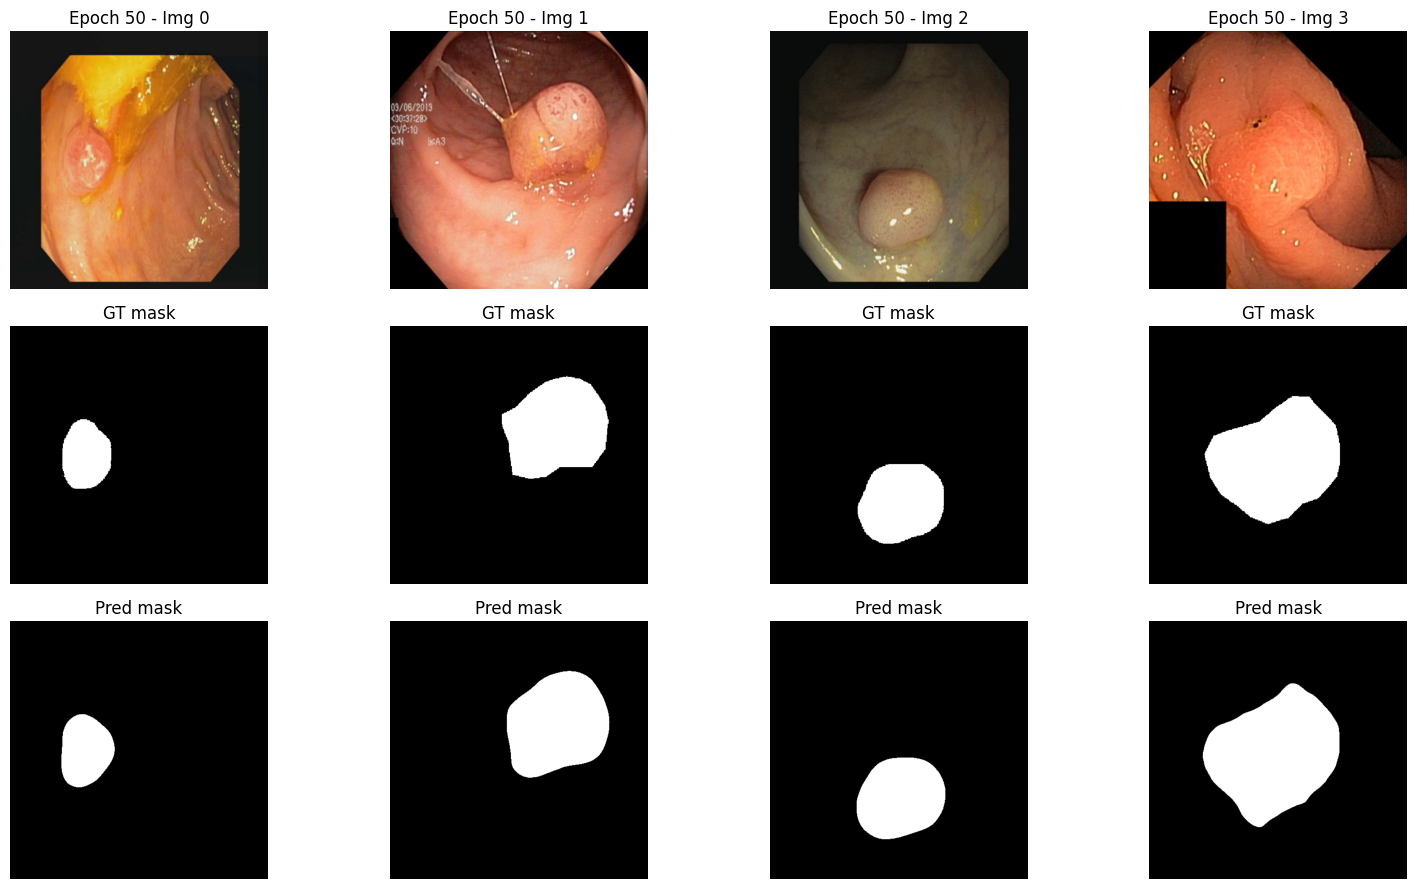

  ✓ New best model saved (Dice: 0.9093)


  ✓ New best model saved (Dice: 0.9127)



Epoch 60/500
  Train loss: 0.0566 | Dice: 0.9267 | IoU: 0.8689
  Sensitivity: 0.9273 | Precision: 0.9331
  Val   loss: 0.1050 | Dice: 0.9045 | IoU: 0.8318
  Sensitivity: 0.9382 | Precision: 0.8815


  ✓ New best model saved (Dice: 0.9146)


  ✓ New best model saved (Dice: 0.9158)


  ✓ New best model saved (Dice: 0.9221)



Epoch 80/500
  Train loss: 0.0476 | Dice: 0.9368 | IoU: 0.8859
  Sensitivity: 0.9379 | Precision: 0.9390
  Val   loss: 0.0897 | Dice: 0.9160 | IoU: 0.8498
  Sensitivity: 0.9368 | Precision: 0.9031



Epoch 100/500
  Train loss: 0.0431 | Dice: 0.9403 | IoU: 0.8928
  Sensitivity: 0.9406 | Precision: 0.9432
  Val   loss: 0.0951 | Dice: 0.9173 | IoU: 0.8524
  Sensitivity: 0.9378 | Precision: 0.9051


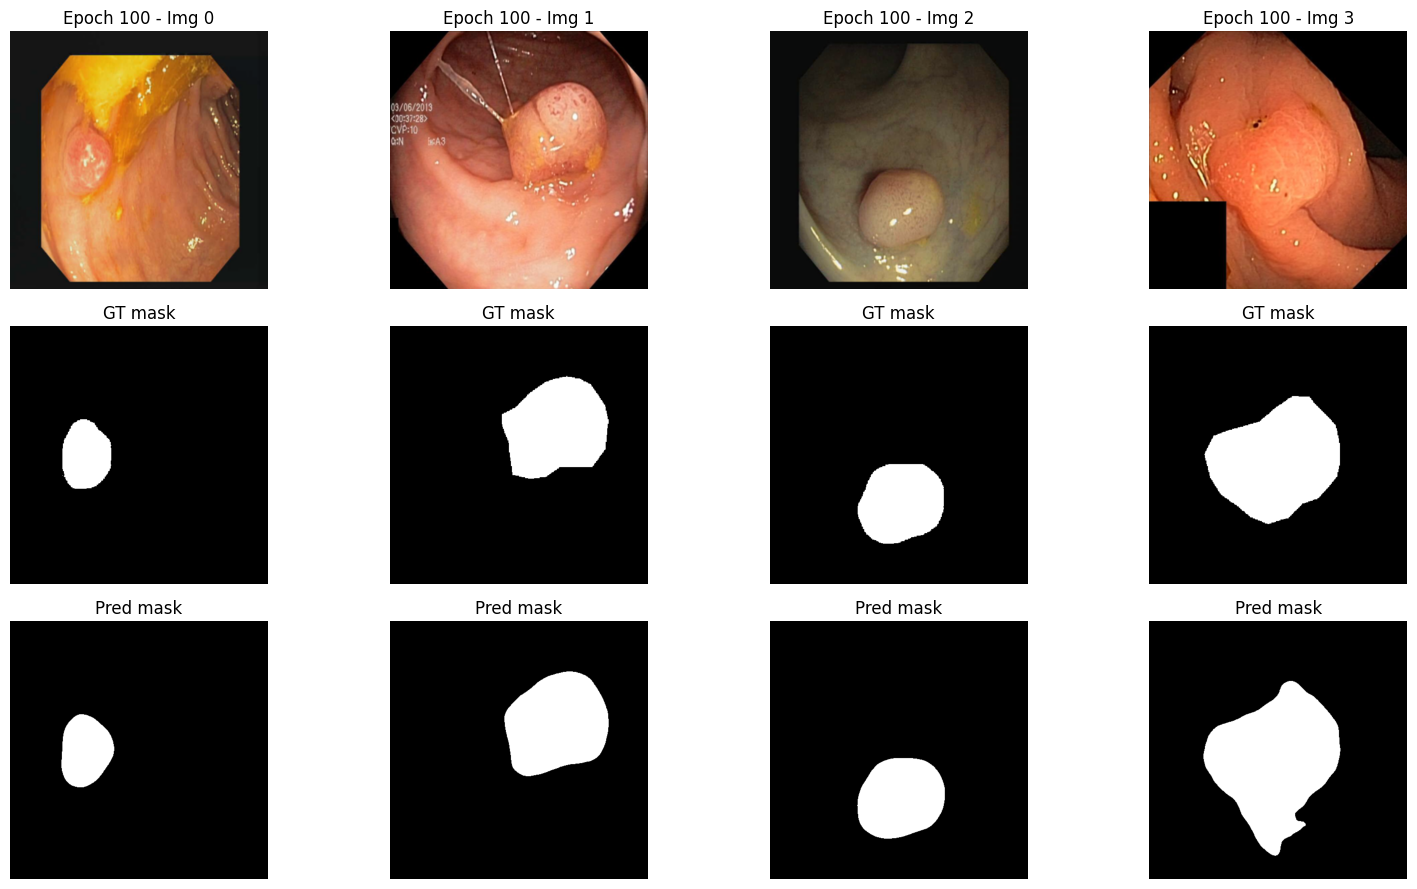


Epoch 120/500
  Train loss: 0.0436 | Dice: 0.9429 | IoU: 0.8948
  Sensitivity: 0.9416 | Precision: 0.9468
  Val   loss: 0.0968 | Dice: 0.9145 | IoU: 0.8478
  Sensitivity: 0.9231 | Precision: 0.9140



Epoch 140/500
  Train loss: 0.0381 | Dice: 0.9476 | IoU: 0.9033
  Sensitivity: 0.9462 | Precision: 0.9500
  Val   loss: 0.0928 | Dice: 0.9162 | IoU: 0.8502
  Sensitivity: 0.9441 | Precision: 0.8980


  ✓ New best model saved (Dice: 0.9244)


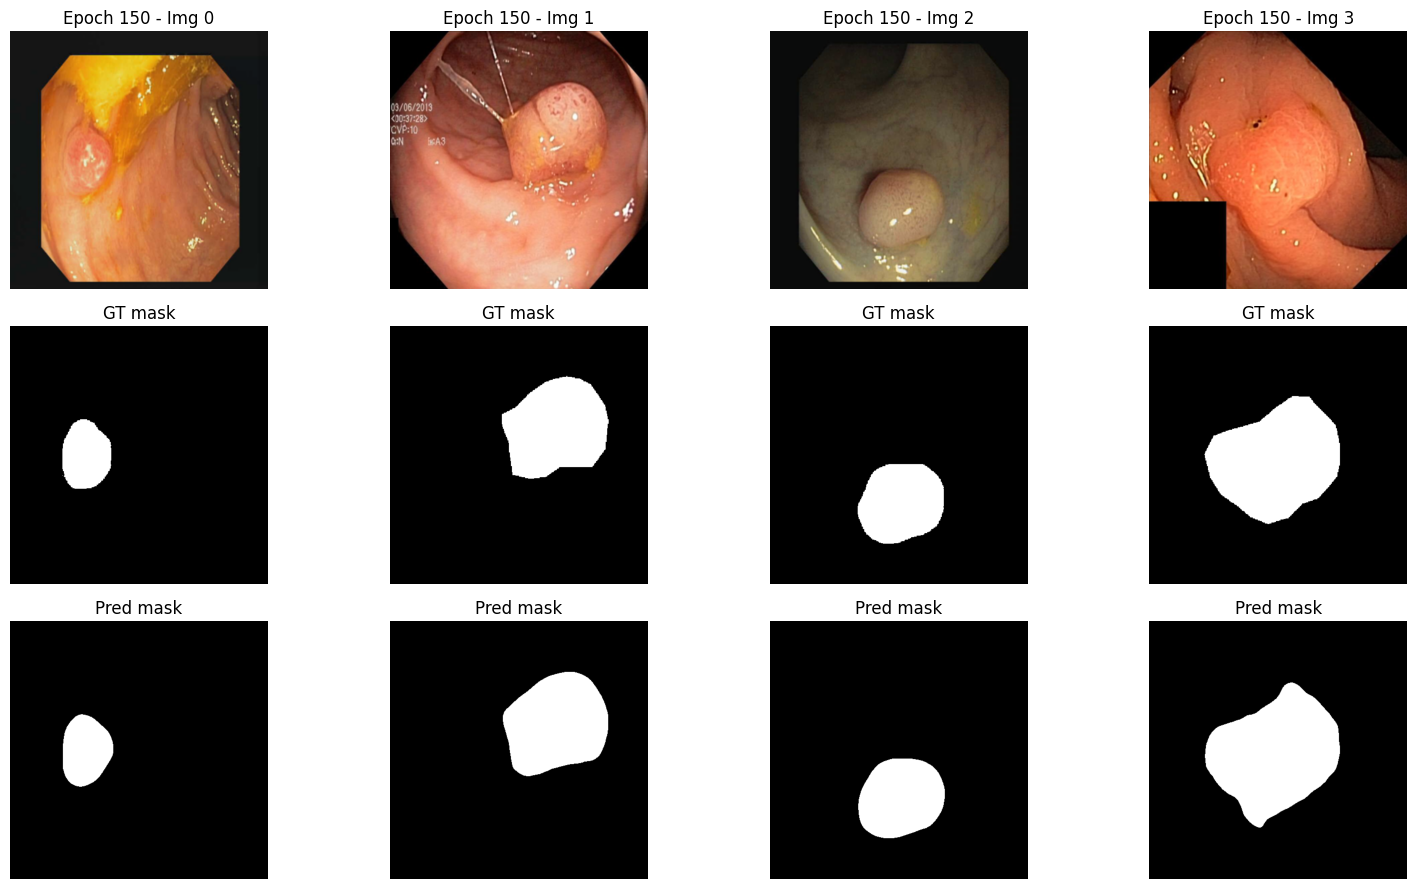


Epoch 160/500
  Train loss: 0.0366 | Dice: 0.9481 | IoU: 0.9051
  Sensitivity: 0.9469 | Precision: 0.9509
  Val   loss: 0.1003 | Dice: 0.9189 | IoU: 0.8552
  Sensitivity: 0.9045 | Precision: 0.9410



Epoch 180/500
  Train loss: 0.0362 | Dice: 0.9481 | IoU: 0.9073
  Sensitivity: 0.9491 | Precision: 0.9499
  Val   loss: 0.0951 | Dice: 0.9210 | IoU: 0.8590
  Sensitivity: 0.9273 | Precision: 0.9226



Epoch 200/500
  Train loss: 0.0326 | Dice: 0.9535 | IoU: 0.9145
  Sensitivity: 0.9536 | Precision: 0.9551
  Val   loss: 0.0940 | Dice: 0.9216 | IoU: 0.8598
  Sensitivity: 0.9349 | Precision: 0.9170


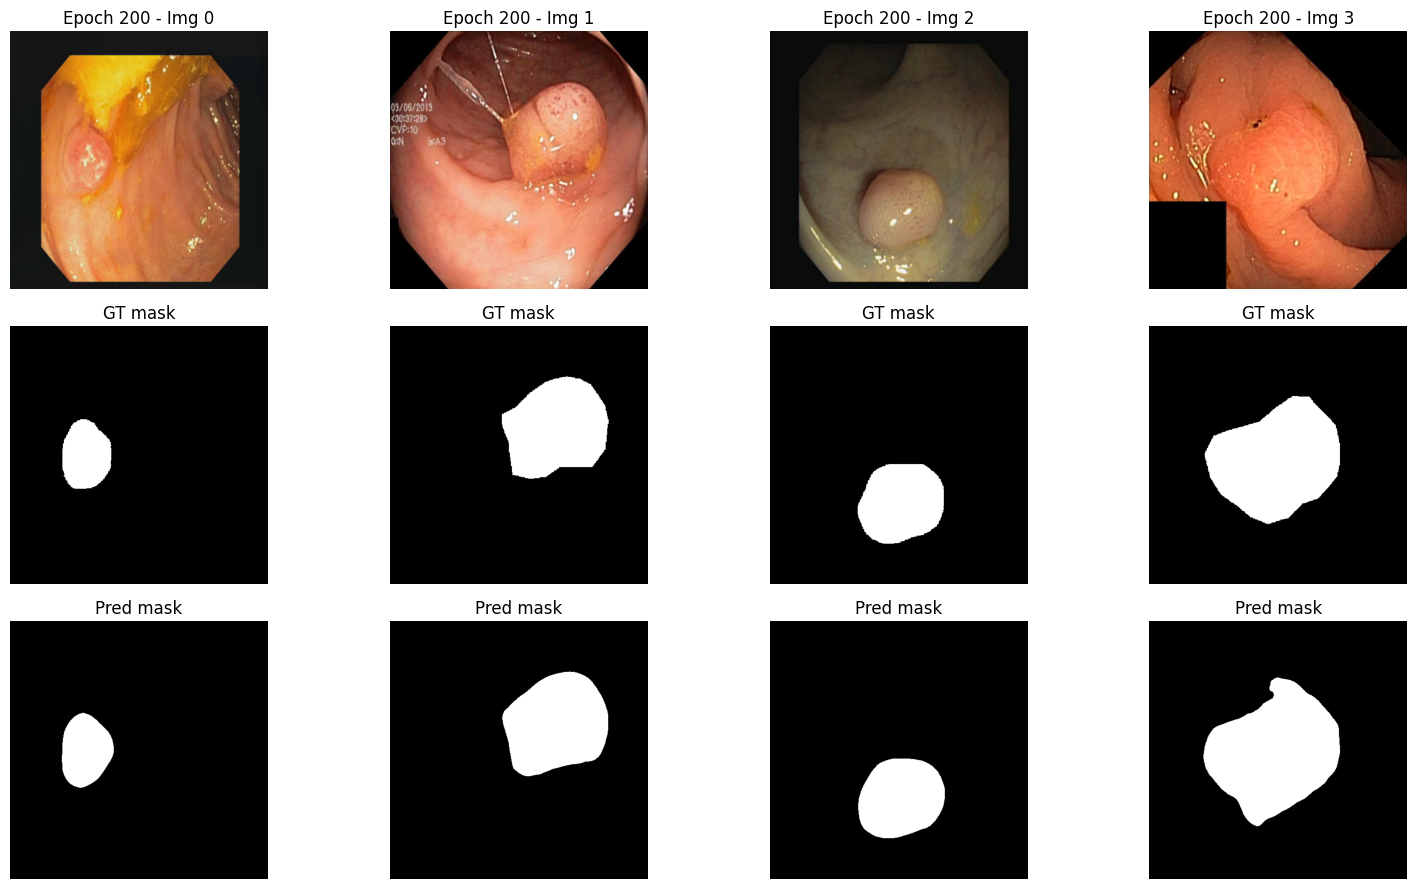


Epoch 220/500
  Train loss: 0.0336 | Dice: 0.9543 | IoU: 0.9151
  Sensitivity: 0.9525 | Precision: 0.9569
  Val   loss: 0.1000 | Dice: 0.9118 | IoU: 0.8437
  Sensitivity: 0.9401 | Precision: 0.8932


  ✓ New best model saved (Dice: 0.9262)



Epoch 240/500
  Train loss: 0.0382 | Dice: 0.9453 | IoU: 0.9015
  Sensitivity: 0.9458 | Precision: 0.9467
  Val   loss: 0.0882 | Dice: 0.9243 | IoU: 0.8640
  Sensitivity: 0.9326 | Precision: 0.9240


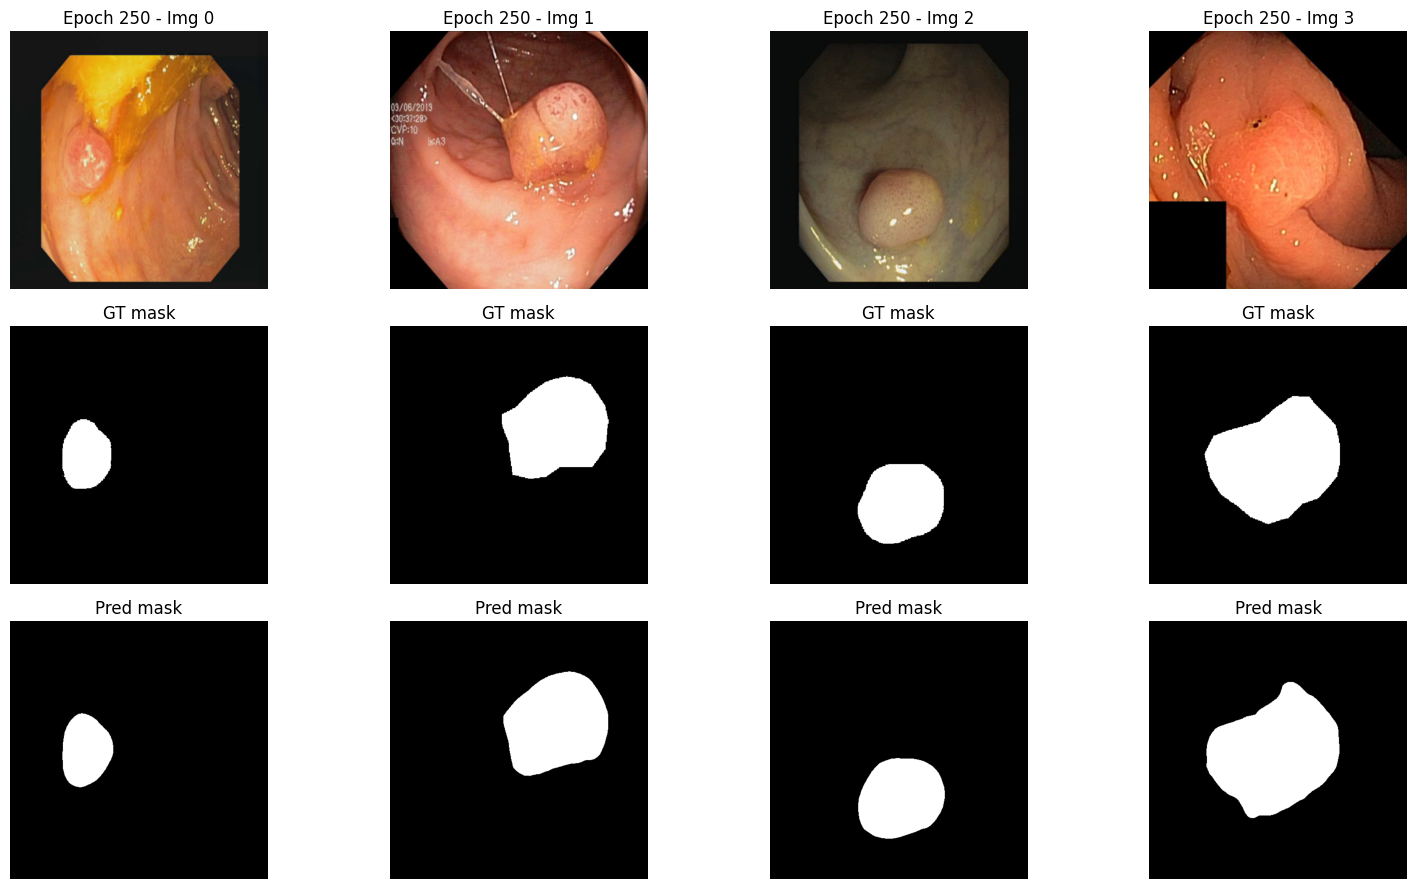


Epoch 260/500
  Train loss: 0.0352 | Dice: 0.9477 | IoU: 0.9076
  Sensitivity: 0.9509 | Precision: 0.9481
  Val   loss: 0.0914 | Dice: 0.9255 | IoU: 0.8664
  Sensitivity: 0.9284 | Precision: 0.9280



Epoch 280/500
  Train loss: 0.0272 | Dice: 0.9626 | IoU: 0.9288
  Sensitivity: 0.9616 | Precision: 0.9643
  Val   loss: 0.0944 | Dice: 0.9231 | IoU: 0.8620
  Sensitivity: 0.9264 | Precision: 0.9268


  ✓ New best model saved (Dice: 0.9264)



Epoch 300/500
  Train loss: 0.0305 | Dice: 0.9579 | IoU: 0.9214
  Sensitivity: 0.9574 | Precision: 0.9597
  Val   loss: 0.0944 | Dice: 0.9226 | IoU: 0.8621
  Sensitivity: 0.9324 | Precision: 0.9192


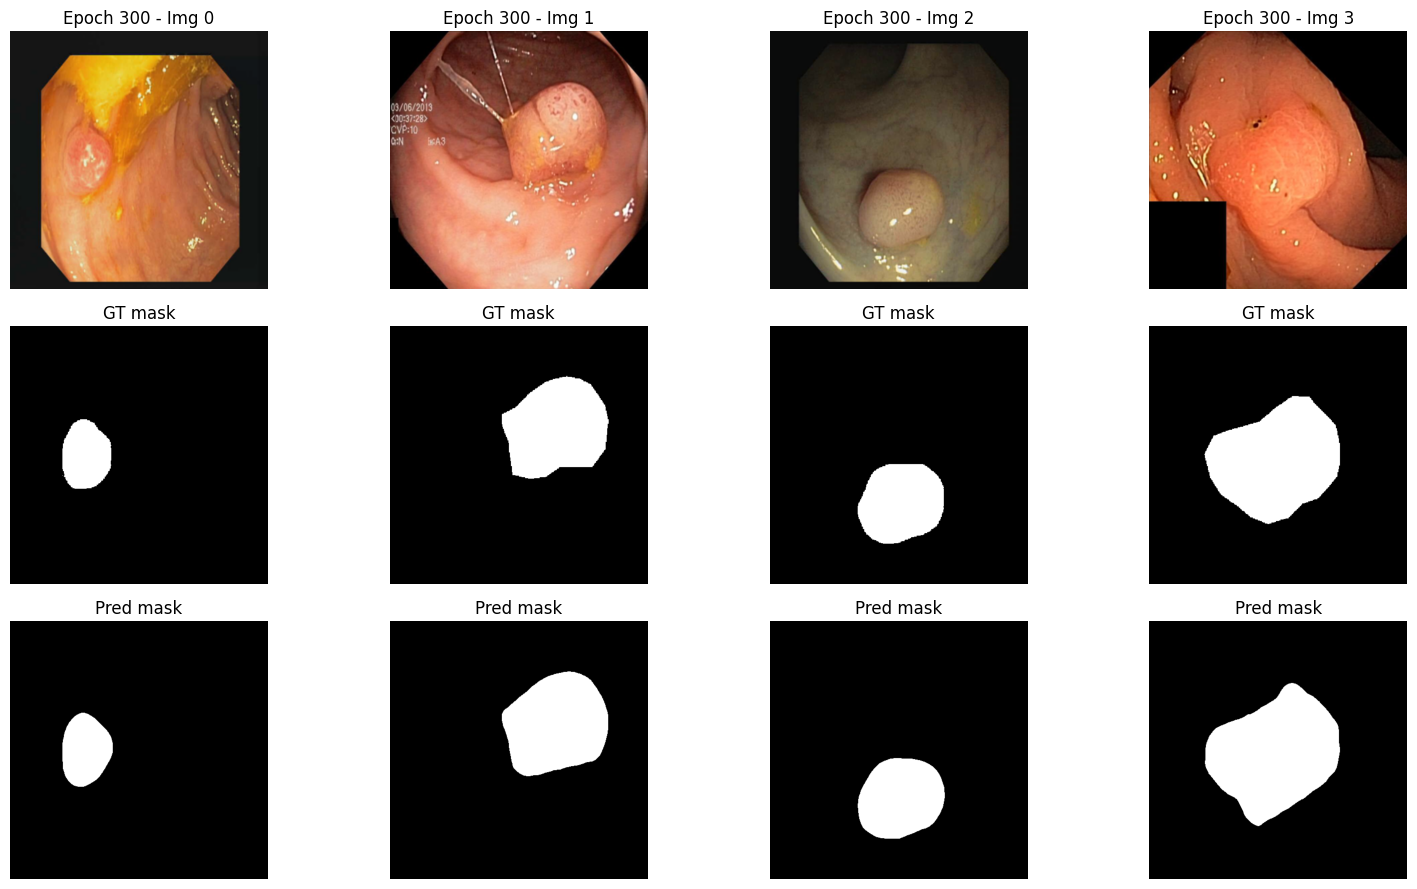


Epoch 320/500
  Train loss: 0.0287 | Dice: 0.9578 | IoU: 0.9231
  Sensitivity: 0.9573 | Precision: 0.9593
  Val   loss: 0.0961 | Dice: 0.9217 | IoU: 0.8599
  Sensitivity: 0.9317 | Precision: 0.9195



Epoch 340/500
  Train loss: 0.0290 | Dice: 0.9574 | IoU: 0.9223
  Sensitivity: 0.9564 | Precision: 0.9602
  Val   loss: 0.1008 | Dice: 0.9228 | IoU: 0.8611
  Sensitivity: 0.9169 | Precision: 0.9332


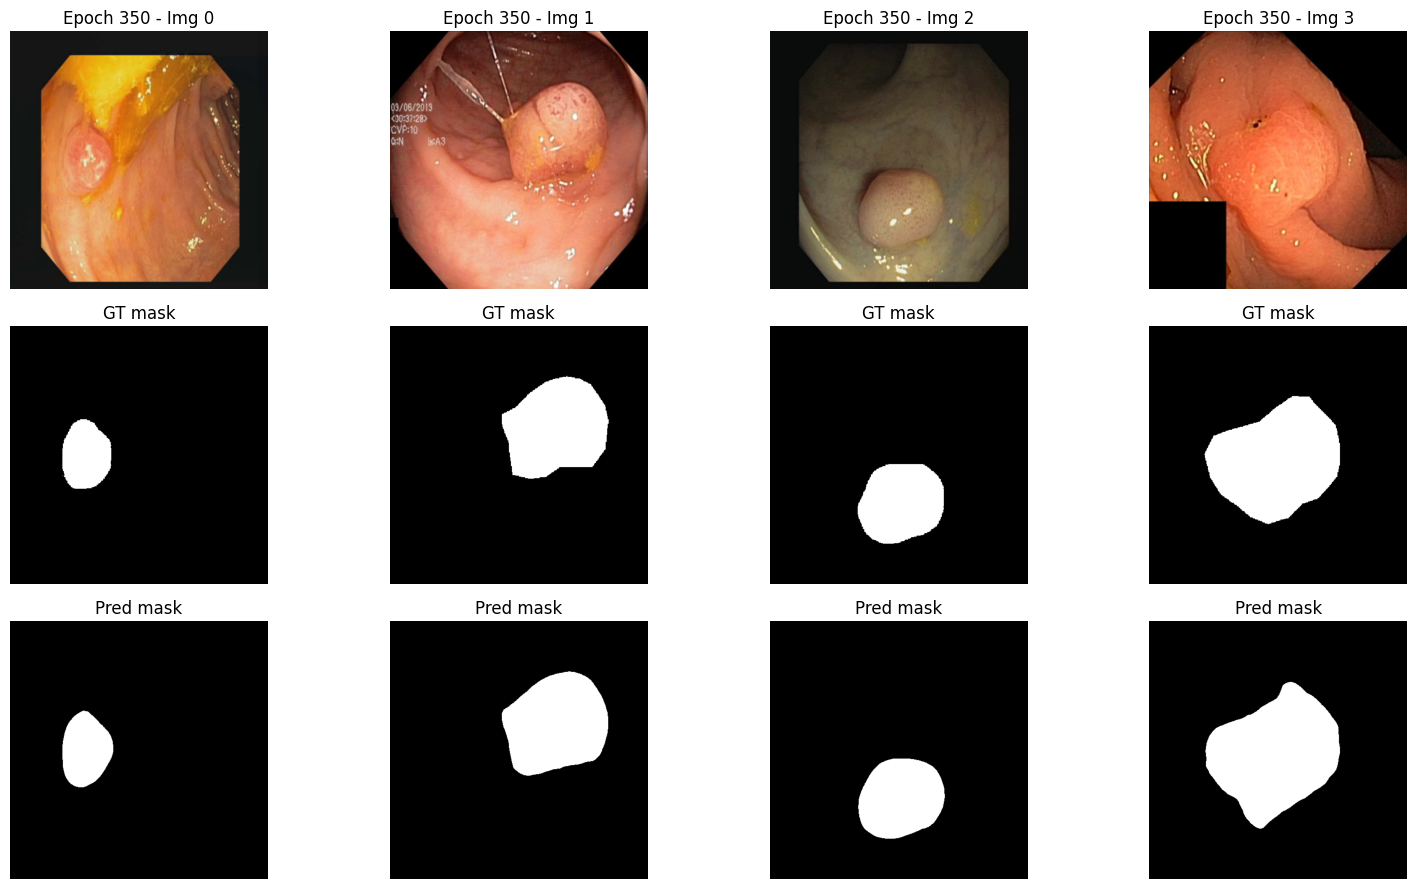


Epoch 360/500
  Train loss: 0.0248 | Dice: 0.9646 | IoU: 0.9335
  Sensitivity: 0.9625 | Precision: 0.9675
  Val   loss: 0.1015 | Dice: 0.9217 | IoU: 0.8602
  Sensitivity: 0.9269 | Precision: 0.9226



Epoch 380/500
  Train loss: 0.0246 | Dice: 0.9646 | IoU: 0.9339
  Sensitivity: 0.9638 | Precision: 0.9659
  Val   loss: 0.0965 | Dice: 0.9257 | IoU: 0.8656
  Sensitivity: 0.9228 | Precision: 0.9333


  Early stopping at epoch 384

Best Val Dice: 0.9264

FINAL EVALUATION ON ALL TEST SETS

FINAL EVALUATION ON ALL TEST SETS (NO TTA)

Evaluating Kvasir... (TTA=False)
  Dice: 0.9062 | IoU: 0.8345
  Sensitivity: 0.8616 | Precision: 0.9631
  Hausdorff95: 195.63 | ASSD: 9.19

Evaluating CVC-ClinicDB... (TTA=False)
  Dice: 0.9305 | IoU: 0.8751
  Sensitivity: 0.9291 | Precision: 0.9368
  Hausdorff95: 59.02 | ASSD: 4.51

Evaluating CVC-ColonDB... (TTA=False)
  Dice: 0.7935 | IoU: 0.6992
  Sensitivity: 0.8245 | Precision: 0.8191
  Hausdorff95: 126.72 | ASSD: 17.81

Evaluating ETIS-LaribPolypDB... (TTA=False)
  Dice: 0.7807 | IoU: 0.6833
  Sensitivity: 0.9019 | Precision: 0.7289
  Hausdorff95: 145.60 | ASSD: 15.85

Evaluating CVC-300... (TTA=False)
  Dice: 0.8987 | IoU: 0.8304
  Sensitivity: 0.9403 | Precision: 0.8775
  Hausdorff95: 31.96 | ASSD: 4.74

FINAL EVALUATION ON ALL TEST SETS (TTA: flip/rot90 with inverse-align)

Evaluating Kvasir... (TTA=True)
  Dice: 0.9168 | IoU: 0.8491
  Sensitivi

In [17]:
# Train with comprehensive evaluation
best_state, history, test_results = fit(
    model=model,
    loaders=loaders,
    device=device,
    epochs=500,
    lr=1e-5,
    threshold=0.5,
    visualize_every=50,  # Visualize every 60 epochs
    print_every=20,  # Print training and evaluation metrics every 20 epochs
)

# Save final model
torch.save(model.state_dict(), "Poly_New_model.pth")
print("Training completed!")

## Evaluation

In [18]:
import pandas as pd

def build_main_result_tables(no_tta_csv="polygap_Poly_New_no_tta.csv",
                             tta_csv="polygap_Poly_New_tta.csv",
                             out_main="results_table_main.csv",
                             out_avg="results_table_macro_avg.csv"):
    df_no = pd.read_csv(no_tta_csv, index_col=0)
    df_tta = pd.read_csv(tta_csv, index_col=0)

    # Keep core paper metrics
    keep = ["Dice","IoU","Sensitivity","Precision","Hausdorff95","ASSD"]
    df_no = df_no[keep].copy()
    df_tta = df_tta[keep].copy()

    df_no.columns = [f"{c}_NoTTA" for c in df_no.columns]
    df_tta.columns = [f"{c}_TTA" for c in df_tta.columns]

    df = pd.concat([df_no, df_tta], axis=1)

    # Add deltas
    for c in keep:
        df[f"{c}_Delta(TTA-NoTTA)"] = df[f"{c}_TTA"] - df[f"{c}_NoTTA"]

    # Macro average row
    avg_row = df.mean(axis=0).to_frame().T
    avg_row.index = ["MacroAvg"]
    df_all = pd.concat([df, avg_row], axis=0)

    df_all.to_csv(out_main)

    # Separate macro-average-only table
    avg_row.to_csv(out_avg)
    print(f"Saved {out_main} and {out_avg}")

build_main_result_tables()

Saved results_table_main.csv and results_table_macro_avg.csv


## Visualizations

In [19]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch

def denorm_img(img_t):
    # img_t: [3,H,W] normalized
    mean = torch.tensor([0.485,0.456,0.406], device=img_t.device)[:,None,None]
    std  = torch.tensor([0.229,0.224,0.225], device=img_t.device)[:,None,None]
    x = img_t*std + mean
    return x.clamp(0,1)

@torch.no_grad()
def predict_masks(model, imgs, threshold=0.5, use_tta=False):
    if use_tta:
        logits = tta_logits(model, imgs)
    else:
        logits = model(imgs)
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()
    return preds, probs

def save_qualitative_grid(model, dl_test, dataset_name, device, threshold=0.5, n=4, out_dir="qualitative"):
    os.makedirs(out_dir, exist_ok=True)
    model.eval()

    # Rebuild a loader that returns paths (so you can cite examples)
    ds = dl_test.dataset
    ds.return_path = True  # enable path return

    batch = next(iter(dl_test))
    imgs, masks, img_paths, mask_paths = batch
    imgs, masks = imgs.to(device), masks.to(device)

    preds_no, _ = predict_masks(model, imgs, threshold, use_tta=False)
    preds_tta, _ = predict_masks(model, imgs, threshold, use_tta=True)

    imgs = imgs[:n]; masks = masks[:n]
    preds_no = preds_no[:n]; preds_tta = preds_tta[:n]
    img_paths = img_paths[:n]

    fig, axes = plt.subplots(n, 4, figsize=(16, 4*n))
    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(n):
        img = denorm_img(imgs[i]).permute(1,2,0).detach().cpu().numpy()
        gt = masks[i,0].detach().cpu().numpy()
        p0 = preds_no[i,0].detach().cpu().numpy()
        p1 = preds_tta[i,0].detach().cpu().numpy()

        axes[i,0].imshow(img); axes[i,0].set_title("Image"); axes[i,0].axis("off")
        axes[i,1].imshow(gt, cmap="gray"); axes[i,1].set_title("GT"); axes[i,1].axis("off")
        axes[i,2].imshow(p0, cmap="gray"); axes[i,2].set_title("Pred (NoTTA)"); axes[i,2].axis("off")
        axes[i,3].imshow(p1, cmap="gray"); axes[i,3].set_title("Pred (TTA)"); axes[i,3].axis("off")

    plt.tight_layout()
    out_path = os.path.join(out_dir, f"qual_{dataset_name}_grid.png")
    plt.savefig(out_path, dpi=200)
    plt.close()
    print(f"Saved {out_path}")

# Run for each test dataset after loading best model
for name, dl in loaders["test_sets"].items():
    save_qualitative_grid(model, dl, name, device, threshold=0.5, n=4)

Saved qualitative\qual_Kvasir_grid.png
Saved qualitative\qual_CVC-ClinicDB_grid.png
Saved qualitative\qual_CVC-ColonDB_grid.png
Saved qualitative\qual_ETIS-LaribPolypDB_grid.png
Saved qualitative\qual_CVC-300_grid.png


## Per-image metrics + per-dataset CSV export (NoTTA and TTA)

In [20]:
import numpy as np
import pandas as pd
import torch
from scipy.spatial import cKDTree
from scipy.spatial.distance import directed_hausdorff
from scipy.ndimage import binary_erosion

# ---------- Per-image boundary helpers ----------
def _get_boundary_points(mask_np: np.ndarray):
    mask_bool = mask_np.astype(bool)
    eroded = binary_erosion(mask_bool)
    boundary = mask_bool ^ eroded
    return np.argwhere(boundary)

def _avg_distance(set1, set2):
    if len(set1) == 0 or len(set2) == 0:
        return 0.0
    tree = cKDTree(set2)
    distances, _ = tree.query(set1)
    return float(np.mean(distances))

def hd95_single(pred_np: np.ndarray, gt_np: np.ndarray):
    pb = _get_boundary_points(pred_np)
    gb = _get_boundary_points(gt_np)
    if len(pb) == 0 or len(gb) == 0:
        return 0.0
    hd1 = directed_hausdorff(pb, gb)[0]
    hd2 = directed_hausdorff(gb, pb)[0]
    return float(max(hd1, hd2))

def assd_single(pred_np: np.ndarray, gt_np: np.ndarray):
    pb = _get_boundary_points(pred_np)
    gb = _get_boundary_points(gt_np)
    if len(pb) == 0 or len(gb) == 0:
        return 0.0
    d1 = _avg_distance(pb, gb)
    d2 = _avg_distance(gb, pb)
    return float((d1 + d2) / 2.0)

def rvd_single(pred_t: torch.Tensor, gt_t: torch.Tensor):
    pv = float(pred_t.sum().item())
    gv = float(gt_t.sum().item())
    if gv <= 0:
        return 0.0
    return float((pv - gv) / gv)

# ---------- Per-image metric computation ----------
def compute_metrics_per_image(pred: torch.Tensor, gt: torch.Tensor, smooth=1e-6):
    """
    pred, gt: [B,1,H,W] binary float tensors {0,1}
    returns list of dicts length B
    """
    if pred.ndim == 3:
        pred = pred[:, None, ...]
    if gt.ndim == 3:
        gt = gt[:, None, ...]

    B = pred.shape[0]
    out = []

    for i in range(B):
        p = pred[i].view(-1)
        g = gt[i].view(-1)

        tp = ((p == 1) & (g == 1)).sum().float()
        tn = ((p == 0) & (g == 0)).sum().float()
        fp = ((p == 1) & (g == 0)).sum().float()
        fn = ((p == 0) & (g == 1)).sum().float()

        dice = (2*tp + smooth) / (2*tp + fp + fn + smooth)
        iou  = (tp + smooth) / (tp + fp + fn + smooth)
        sens = (tp + smooth) / (tp + fn + smooth)
        spec = (tn + smooth) / (tn + fp + smooth)
        prec = (tp + smooth) / (tp + fp + smooth)
        acc  = (tp + tn + smooth) / (tp + tn + fp + fn + smooth)

        beta = 2
        f2 = (1 + beta**2) * (prec * sens) / (beta**2 * prec + sens + smooth)

        # boundary metrics on CPU numpy
        pred_np = pred[i,0].detach().cpu().numpy().astype(np.uint8)
        gt_np   = gt[i,0].detach().cpu().numpy().astype(np.uint8)

        hd = hd95_single(pred_np, gt_np)
        asd = assd_single(pred_np, gt_np)
        rvd = rvd_single(pred[i,0], gt[i,0])

        out.append({
            "Dice": float(dice.item()),
            "IoU": float(iou.item()),
            "Sensitivity": float(sens.item()),
            "Specificity": float(spec.item()),
            "Precision": float(prec.item()),
            "Accuracy": float(acc.item()),
            "F2_Score": float(f2.item()),
            "Hausdorff95": float(hd),
            "ASSD": float(asd),
            "RVD": float(rvd),
        })

    return out

@torch.no_grad()
def evaluate_dataset_per_image(model, dl, device, threshold=0.5, use_tta=False):
    """
    Returns:
      df_img: per-image metrics (one row per image)
      df_summary: mean/median/std summary
    """
    model.eval()
    rows = []

    for batch in dl:
        # supports both (img,mask) and (img,mask,paths...)
        imgs = batch[0].to(device)
        gts  = batch[1].to(device)

        if use_tta:
            logits = tta_logits(model, imgs)
        else:
            logits = model(imgs)

        preds = (torch.sigmoid(logits) > threshold).float()

        metrics_list = compute_metrics_per_image(preds, gts)
        for m in metrics_list:
            rows.append(m)

    df_img = pd.DataFrame(rows)

    df_summary = pd.DataFrame({
        "mean": df_img.mean(numeric_only=True),
        "median": df_img.median(numeric_only=True),
        "std": df_img.std(numeric_only=True),
    })

    return df_img, df_summary

def evaluate_all_test_sets_per_image(model, test_sets, device, threshold=0.5, use_tta=False, out_dir="per_image_metrics"):
    import os
    os.makedirs(out_dir, exist_ok=True)

    summaries = {}
    for name, dl in test_sets.items():
        df_img, df_sum = evaluate_dataset_per_image(model, dl, device, threshold=threshold, use_tta=use_tta)
        df_img.to_csv(f"{out_dir}/{name}_per_image_{'TTA' if use_tta else 'NoTTA'}.csv", index=False)

        # store mean row for quick table
        summaries[name] = df_sum["mean"].to_dict()

        print(f"[{name}] saved per-image CSV. Mean Dice={df_sum.loc['Dice','mean']:.4f}")

    df_summary_table = pd.DataFrame(summaries).T
    df_summary_table.to_csv(f"{out_dir}/summary_{'TTA' if use_tta else 'NoTTA'}.csv")
    return df_summary_table


In [21]:
# model.load_state_dict(... best ...)
summary_no = evaluate_all_test_sets_per_image(model, loaders["test_sets"], device, threshold=0.5, use_tta=False)
summary_tt = evaluate_all_test_sets_per_image(model, loaders["test_sets"], device, threshold=0.5, use_tta=True)

[Kvasir] saved per-image CSV. Mean Dice=0.8952
[CVC-ClinicDB] saved per-image CSV. Mean Dice=0.9238
[CVC-ColonDB] saved per-image CSV. Mean Dice=0.7912
[ETIS-LaribPolypDB] saved per-image CSV. Mean Dice=0.7931
[CVC-300] saved per-image CSV. Mean Dice=0.8935
[Kvasir] saved per-image CSV. Mean Dice=0.9080
[CVC-ClinicDB] saved per-image CSV. Mean Dice=0.9302
[CVC-ColonDB] saved per-image CSV. Mean Dice=0.7998
[ETIS-LaribPolypDB] saved per-image CSV. Mean Dice=0.8102
[CVC-300] saved per-image CSV. Mean Dice=0.8941


## 3) Parameter count, latency (ms/image), peak GPU memory (NoTTA and TTA)

In [22]:
import time
import torch

def count_params(model):
    return sum(p.numel() for p in model.parameters())

@torch.no_grad()
def benchmark_inference(model, dl, device, use_tta=False, n_warmup=10, n_batches=30):
    assert torch.cuda.is_available(), "Benchmark intended for CUDA for reliable timing/memory."
    model.eval()

    # warmup
    it = iter(dl)
    for _ in range(n_warmup):
        try:
            batch = next(it)
        except StopIteration:
            it = iter(dl)
            batch = next(it)
        imgs = batch[0].to(device)
        _ = tta_logits(model, imgs) if use_tta else model(imgs)

    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats(device)

    # timed run
    start_event = torch.cuda.Event(enable_timing=True)
    end_event   = torch.cuda.Event(enable_timing=True)

    total_ms = 0.0
    total_imgs = 0

    it = iter(dl)
    for _ in range(n_batches):
        try:
            batch = next(it)
        except StopIteration:
            break

        imgs = batch[0].to(device)
        bsz = imgs.size(0)

        start_event.record()
        _ = tta_logits(model, imgs) if use_tta else model(imgs)
        end_event.record()

        torch.cuda.synchronize()
        total_ms += start_event.elapsed_time(end_event)
        total_imgs += bsz

    peak_mem_mb = torch.cuda.max_memory_allocated(device) / (1024**2)
    ms_per_img = total_ms / max(1, total_imgs)

    return ms_per_img, peak_mem_mb

def run_efficiency_report(model, test_sets, device, report_csv="efficiency_report.csv"):
    params = count_params(model)
    params_m = params / 1e6

    # Choose a representative loader for benchmarking
    # (use one dataset; or concatenate if you prefer)
    dl = next(iter(test_sets.values()))

    ms_no, mem_no = benchmark_inference(model, dl, device, use_tta=False)
    ms_tt, mem_tt = benchmark_inference(model, dl, device, use_tta=True)

    df = pd.DataFrame([{
        "Params(M)": params_m,
        "Latency_ms_per_img_NoTTA": ms_no,
        "PeakMem_MB_NoTTA": mem_no,
        "Latency_ms_per_img_TTA": ms_tt,
        "PeakMem_MB_TTA": mem_tt,
        "LatencyMultiplier_TTA/NoTTA": ms_tt / max(1e-9, ms_no),
    }])
    df.to_csv(report_csv, index=False)
    print(df)
    print(f"Saved {report_csv}")
    return df

In [23]:
# after loading best model weights:
eff_df = run_efficiency_report(model, loaders["test_sets"], device, report_csv="efficiency_report.csv")

   Params(M)  Latency_ms_per_img_NoTTA  PeakMem_MB_NoTTA  \
0  28.379393                  13.49907        980.914062   

   Latency_ms_per_img_TTA  PeakMem_MB_TTA  LatencyMultiplier_TTA/NoTTA  
0               81.452998     1010.914062                     6.033971  
Saved efficiency_report.csv


## Gradcam

In [24]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

class SegGradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self.h1 = target_layer.register_forward_hook(self._forward_hook)
        self.h2 = target_layer.register_full_backward_hook(self._backward_hook)

    def _forward_hook(self, module, inp, out):
        self.activations = out

    def _backward_hook(self, module, grad_in, grad_out):
        self.gradients = grad_out[0]

    def close(self):
        self.h1.remove()
        self.h2.remove()

    def __call__(self, img, gt_mask=None, target_mode="gt_mean", cam_power=0.7):
        """
        target_mode:
        - "gt_mean": mean logit inside GT mask (your current)
        - "pred_mean": mean logit inside predicted mask
        - "max": max logit anywhere (often strongest)
        - "sum": sum logits (strong but less localized)
        cam_power: <1 boosts contrast (e.g., 0.7 or 0.5)
        """
        self.model.eval()
        dev = next(self.model.parameters()).device

        img = img.to(dev).requires_grad_(True)
        logits = self.model(img)  # [1,1,H,W]

        if target_mode == "max":
            target = logits.max()

        elif target_mode == "sum":
            target = logits.sum()

        else:
            # build mask depending on mode
            if target_mode == "pred_mean":
                with torch.no_grad():
                    mask = (torch.sigmoid(logits) > 0.5).float()
            else:
                # default gt_mean
                if gt_mask is None:
                    with torch.no_grad():
                        mask = (torch.sigmoid(logits) > 0.5).float()
                else:
                    mask = gt_mask.to(dev)

            target = (logits * mask).sum() / (mask.sum() + 1e-6)

        self.model.zero_grad(set_to_none=True)
        target.backward(retain_graph=True)

        A = self.activations
        dA = self.gradients
        weights = dA.mean(dim=(2, 3), keepdim=True)
        cam = (weights * A).sum(dim=1, keepdim=True)
        cam = F.relu(cam)

        cam = F.interpolate(cam, size=img.shape[2:], mode="bilinear", align_corners=False)
        cam = cam[0, 0].detach().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

        # contrast boost
        cam = np.power(cam, cam_power)
        return cam

In [ ]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt

# ---------- assumes your SegGradCAM class is already defined exactly as you pasted ----------

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def denorm_to_numpy(img_t):
    img = img_t.detach().cpu().float().permute(1, 2, 0).numpy()
    img = img * IMAGENET_STD + IMAGENET_MEAN
    img = np.clip(img, 0, 1)
    return img

def plot_4panel(img_np, gt_np, pred_np, cam_np, save_path=None, figsize=(6,4), title=None, alpha=0.65):
    fig, ax = plt.subplots(1, 4, figsize=figsize)

    ax[0].imshow(img_np)
    ax[0].set_title("Original")
    ax[0].axis("off")

    ax[1].imshow(gt_np, cmap="gray")
    ax[1].set_title("GT mask")
    ax[1].axis("off")

    ax[2].imshow(pred_np, cmap="gray")
    ax[2].set_title("Pred mask")
    ax[2].axis("off")

    ax[3].imshow(img_np)
    ax[3].imshow(cam_np, cmap="jet", alpha=alpha)
    ax[3].set_title("Grad-CAM")
    ax[3].axis("off")

    if title is not None:
        fig.suptitle(title, fontsize=10)

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")
        plt.close(fig)
    else:
        plt.show()


@torch.no_grad()
def get_pred_mask(model, img1, threshold=0.5, use_tta=False):
    if use_tta:
        logits = tta_logits(model, img1)
    else:
        logits = model(img1)
    prob = torch.sigmoid(logits)
    pred = (prob > threshold).float()
    return pred


def gradcam_whole_testset(
    model,
    dl_test,
    dataset_name,
    device,
    target_layer=None,           # if None -> uses model.up0
    threshold=0.5,
    use_tta_for_pred=False,      # prediction only (Grad-CAM itself should not use TTA)
    target_mode="max",           # "max" produces stronger CAMs
    cam_power=0.6,               # boosts contrast (<1)
    out_dir="gradcam_outputs",
    figsize=(6,4),
    alpha=0.65,
    max_images=10,
):
    os.makedirs(out_dir, exist_ok=True)
    save_dir = os.path.join(out_dir, dataset_name)
    os.makedirs(save_dir, exist_ok=True)

    model = model.to(device)
    model.eval()

    # choose target layer
    if target_layer is None:
        target_layer = model.up0  # recommended for sharper CAMs

    cam_engine = SegGradCAM(model, target_layer=target_layer)

    count = 0
    for batch in dl_test:
        imgs = batch[0].to(device)
        masks = batch[1].to(device)

        B = imgs.shape[0]
        for i in range(B):
            if (max_images is not None) and (count >= max_images):
                cam_engine.close()
                print(f"Done. Saved {count} Grad-CAM figures to {save_dir}")
                return

            img1 = imgs[i:i+1]    # [1,3,H,W]
            gt1  = masks[i:i+1]   # [1,1,H,W]

            # predicted mask (for panel 3)
            pred1 = get_pred_mask(model, img1, threshold=threshold, use_tta=use_tta_for_pred)

            # grad-cam (use gt1 or pred1 as mask driver)
            # for strongest maps: target_mode="max"
            cam = cam_engine(img1, gt_mask=gt1, target_mode=target_mode, cam_power=cam_power)

            # numpy for plotting
            img_np  = denorm_to_numpy(img1[0])
            gt_np   = gt1[0,0].detach().cpu().numpy()
            pred_np = pred1[0,0].detach().cpu().numpy()

            save_path = os.path.join(save_dir, f"{count:05d}.png")
            plot_4panel(
                img_np, gt_np, pred_np, cam,
                save_path=save_path,
                figsize=figsize,
                title=f"{dataset_name} #{count}",
                alpha=alpha
            )

            count += 1

    cam_engine.close()
    print(f"Done. Saved {count} Grad-CAM figures to {save_dir}")

In [26]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.eval()

for name, dl in loaders["test_sets"].items():
    gradcam_whole_testset(
        model=model,
        dl_test=dl,
        dataset_name=name,
        device=device,
        target_layer=model.up0,      # key change: better than ssm0
        threshold=0.5,
        use_tta_for_pred=False,
        target_mode="max",           # stronger CAM
        cam_power=0.3,               # stronger contrast
        out_dir="gradcam_outputs",
        figsize=(6,4),
        alpha=0.65,
        max_images=10
    )

Done. Saved 10 Grad-CAM figures to gradcam_outputs\Kvasir
Done. Saved 10 Grad-CAM figures to gradcam_outputs\CVC-ClinicDB
Done. Saved 10 Grad-CAM figures to gradcam_outputs\CVC-ColonDB
Done. Saved 10 Grad-CAM figures to gradcam_outputs\ETIS-LaribPolypDB
Done. Saved 10 Grad-CAM figures to gradcam_outputs\CVC-300
